# 3 - Analysis of DVL Data
Finally, we want to evaluate the quality of the glider's merged dataset, with the ultimate goal of creating velocity profiles. 

In [19]:
import pandas as pd
import xarray as xr
import numpy as np

In [20]:
# For this example we will be using CP05MOAS-GL379 D00008, which was deployed at the Pioneer NES array from 2019-09-27 to 2019-11-19.
refdes = 'CP05MOAS-GL379-01-ADCPAM000'
eng_refdes = 'CP05MOAS-GL379-00-ENG000000'
deployment = 8

In [3]:
dep_str = f"{deployment:04d}"  # always 4 digits, e.g., '0008'
glider_name = '-'.join(refdes.split('-')[:2]) # shorten ref des to get glider name

In [4]:
# Load the ADCP Data
adcp = xr.open_dataset(f"../data/raw/{refdes}.deployment{dep_str}.adcp_data.nc").load()

# Load the Science Data
gdac = xr.open_dataset(f"../data/raw/{glider_name}.deployment{dep_str}.science.nc").load()

# Load in the merged glider data set 
glider = xr.open_dataset(f"../data/processed/{glider_name}.deployment{dep_str}.merged.nc").load()

In [7]:
# Need to add the waypoint targets
glider_out = glider.copy()
glider_out

<xarray.Dataset> Size: 3GB
Dimensions:                                    (time: 604054, bin: 30)
Coordinates:
    lon                                        (time) float64 5MB -70.6 ... -...
    depth                                      (time) float64 5MB 0.0 ... 0.0
    lat                                        (time) float64 5MB 40.05 ... 4...
  * bin                                        (bin) int32 120B 0 1 2 ... 28 29
  * time                                       (time) datetime64[ns] 5MB 2019...
Data variables: (12/67)
    corrected_echo_intensity_beam4             (time, bin) float64 145MB 56.1...
    num_cells                                  (time) float32 2MB 30.0 ... 30.0
    ensemble_number                            (time) float32 2MB 1.0 ... 159.0
    transducer_depth                           (time) float32 2MB 1.0 ... 1.0...
    corrected_echo_intensity_beam3             (time, bin) float64 145MB 72.5...
    corrected_echo_intensity_beam2             (time, bin) float64 145MB 63.4...
    ...                                         ...
    glider_precise_lon                         (time) float64 5MB -70.6 ... -...
    glider_roll                                (time) float64 5MB -1.1 ... 1.66
    profile_id                                 (time) int64 5MB 0 0 ... 1387
    vendor_qc_flag                             (time, bin) int64 145MB 1 1 ... 4
    waypoint_lat                               (time) float64 5MB 39.88 ... 0.0
    waypoint_lon                               (time) float64 5MB -70.6 ... 0.0
Attributes: (12/67)
    node:                               GL379
    comment:                            Data produced by the OOI M2M API and ...
    publisher_email:                    
    sourceUrl:                          http://oceanobservatories.org/
    collection_method:                  recovered_host
    stream:                             adcp_velocity_earth
    ...                                 ...
    geospatial_lat_units:               degrees_north
    geospatial_lat_resolution:          0.1
    geospatial_lon_min:                 -70.65249279445464
    geospatial_lon_max:                 -70.37325248678327
    geospatial_lon_units:               degrees_east
    geospatial_lon_resolution:          0.1

In [8]:
glider_out['lat'] = glider_out['lat']

In [9]:
glider_out

<xarray.Dataset> Size: 3GB
Dimensions:                                    (time: 604054, bin: 30)
Coordinates:
    lon                                        (time) float64 5MB -70.6 ... -...
    depth                                      (time) float64 5MB 0.0 ... 0.0
    lat                                        (time) float64 5MB 40.05 ... 4...
  * bin                                        (bin) int32 120B 0 1 2 ... 28 29
  * time                                       (time) datetime64[ns] 5MB 2019...
Data variables: (12/67)
    corrected_echo_intensity_beam4             (time, bin) float64 145MB 56.1...
    num_cells                                  (time) float32 2MB 30.0 ... 30.0
    ensemble_number                            (time) float32 2MB 1.0 ... 159.0
    transducer_depth                           (time) float32 2MB 1.0 ... 1.0...
    corrected_echo_intensity_beam3             (time, bin) float64 145MB 72.5...
    corrected_echo_intensity_beam2             (time, bin) float64 145MB 63.4...
    ...                                         ...
    glider_precise_lon                         (time) float64 5MB -70.6 ... -...
    glider_roll                                (time) float64 5MB -1.1 ... 1.66
    profile_id                                 (time) int64 5MB 0 0 ... 1387
    vendor_qc_flag                             (time, bin) int64 145MB 1 1 ... 4
    waypoint_lat                               (time) float64 5MB 39.88 ... 0.0
    waypoint_lon                               (time) float64 5MB -70.6 ... 0.0
Attributes: (12/67)
    node:                               GL379
    comment:                            Data produced by the OOI M2M API and ...
    publisher_email:                    
    sourceUrl:                          http://oceanobservatories.org/
    collection_method:                  recovered_host
    stream:                             adcp_velocity_earth
    ...                                 ...
    geospatial_lat_units:               degrees_north
    geospatial_lat_resolution:          0.1
    geospatial_lon_min:                 -70.65249279445464
    geospatial_lon_max:                 -70.37325248678327
    geospatial_lon_units:               degrees_east
    geospatial_lon_resolution:          0.1

In [10]:
glider_out['glider_precise_lat'] == glider_out['lat']

<xarray.DataArray (time: 604054)> Size: 604kB
array([False, False, False, ..., False, False, False], shape=(604054,))
Coordinates:
    lon      (time) float64 5MB -70.6 -70.6 -70.6 -70.6 ... -70.53 -70.53 -70.53
    depth    (time) float64 5MB 0.0 0.0 0.0 0.0 0.0 0.0 ... 0.0 0.0 0.0 0.0 0.0
    lat      (time) float64 5MB 40.05 40.05 40.05 40.05 ... 40.12 40.12 40.12
  * time     (time) datetime64[ns] 5MB 2019-09-27T12:28:38.750000128 ... 2019...

In [11]:
#glider_out = glider_out.where(glider.profile_id <= 100, drop=True)
glider_out[['waypoint_lat','waypoint_lon','heading','profile_id']].to_dataframe().iloc[0:300000].to_csv("../data/processed/glider_out.csv")

In [12]:
glider_out[['waypoint_lat','waypoint_lon','heading','profile_id']].to_dataframe().iloc[0:300000]

,waypoint_lat,waypoint_lon,heading,profile_id,lon,depth,lat
time,,,,,,,
2019-09-27 12:28:38.750000128,39.883335,-70.600000,19819.0,0,-70.599466,0.0,40.048823
2019-09-27 12:28:41.720000000,39.883335,-70.600000,19819.0,0,-70.599466,0.0,40.048818
2019-09-27 12:28:45.640000000,39.883335,-70.600000,19819.0,0,-70.599472,0.0,40.048824
2019-09-27 12:28:48.489999872,39.883335,-70.600000,19819.0,0,-70.599463,0.0,40.048820
2019-09-27 12:28:52.400000000,39.883335,-70.600000,19819.0,0,-70.599457,0.0,40.048812
...,...,...,...,...,...,...,...
2019-10-23 13:55:19.190000128,39.833332,-71.166664,28159.0,739,-70.919844,0.0,40.102444
2019-10-23 13:55:22.169999872,39.833332,-71.166664,28260.0,739,-70.919853,0.0,40.102442
2019-10-23 13:55:26.320000000,39.833332,-71.166664,28060.0,739,-70.919864,0.0,40.102440


### Code to identify transcets

In [21]:
import pandas as pd
import numpy as np
import xarray as xr

def identify_glider_transects(ds):
    """
    Identify transects, travel direction, and add identifiers for Slocum glider data.
    
    Parameters:
    -----------
    ds : xarray.Dataset
        Glider data with time as principal dimension.
        Can have lat/lon/depth as either variables or coordinates.
        Required: profile_id (variable), and lat/lon accessible as vars or coords.
    
    Returns:
    --------
    xarray.Dataset with added variables:
        - transect_id: Which transect (1-4)
        - transect_name: Descriptive name (e.g., "North_Edge")
        - principal_direction: Cardinal direction (e.g., "West", "South")
        - profile_identifier: Unique ID (e.g., "T1_W_P0001")
    """
    
    # Helper function to get lat/lon whether they're variables or coordinates
    def get_latlon(dataset):
        if 'lat' in dataset.coords:
            lat = dataset.coords['lat']
            lon = dataset.coords['lon']
        elif 'lat' in dataset.data_vars:
            lat = dataset['lat']
            lon = dataset['lon']
        else:
            raise ValueError("Could not find 'lat' and 'lon' in dataset variables or coordinates")
        return lat, lon
    
    # Define box corners (counter-clockwise)
    box_corners = np.array([
        [40.083332, -70.375000],  # NE corner
        [40.083332, -71.166664],  # NW corner
        [39.833332, -71.166664],  # SW corner
        [39.833332, -70.375000]   # SE corner
    ])
    
    # Define transects (line segments between corners)
    transects = {
        1: {
            'name': 'North_Edge',
            'start': box_corners[0],
            'end': box_corners[1],
            'direction': 'West'
        },
        2: {
            'name': 'West_Edge',
            'start': box_corners[1],
            'end': box_corners[2],
            'direction': 'South'
        },
        3: {
            'name': 'South_Edge',
            'start': box_corners[2],
            'end': box_corners[3],
            'direction': 'East'
        },
        4: {
            'name': 'East_Edge',
            'start': box_corners[3],
            'end': box_corners[0],
            'direction': 'North'
        }
    }
    
    # Get lat/lon whether they're variables or coordinates
    lat, lon = get_latlon(ds)
    
    # Get time (could be variable or coordinate)
    if 'time' in ds.data_vars:
        time = ds['time']
    else:
        time = ds.coords['time']
    
    # Calculate mean position for each profile
    # Convert to pandas for easier groupby operations
    profile_data = pd.DataFrame({
        'profile_id': ds['profile_id'].values,
        'lat': lat.values,
        'lon': lon.values,
        'time': pd.to_datetime(time.values)
    })
    
    # Calculate statistics per profile
    profile_df = profile_data.groupby('profile_id').agg({
        'lat': 'mean',
        'lon': 'mean', 
        'time': 'min'
    }).reset_index()
    
    profile_df.columns = ['profile_id', 'lat_mean', 'lon_mean', 'time_first']
    
    # Sort by time to ensure proper ordering
    profile_df = profile_df.sort_values('time_first').reset_index(drop=True)
    
    # Function to calculate perpendicular distance from point to line segment
    def point_to_segment_distance(point, seg_start, seg_end):
        """Calculate perpendicular distance from point to line segment"""
        # Vector from segment start to end
        seg_vec = seg_end - seg_start
        # Vector from segment start to point
        point_vec = point - seg_start
        
        # Project point onto line
        seg_len_sq = np.dot(seg_vec, seg_vec)
        if seg_len_sq == 0:
            return np.linalg.norm(point_vec)
        
        t = max(0, min(1, np.dot(point_vec, seg_vec) / seg_len_sq))
        projection = seg_start + t * seg_vec
        
        return np.linalg.norm(point - projection)
    
    # Assign each profile to nearest transect
    transect_assignments = []
    
    for _, profile in profile_df.iterrows():
        point = np.array([profile['lat_mean'], profile['lon_mean']])
        
        # Calculate distance to each transect
        distances = {}
        for t_id, t_info in transects.items():
            dist = point_to_segment_distance(point, t_info['start'], t_info['end'])
            distances[t_id] = dist
        
        # Assign to nearest transect
        nearest_transect = min(distances, key=distances.get)
        transect_assignments.append(nearest_transect)
    
    profile_df['transect_id'] = transect_assignments
    
    # Add transect information
    profile_df['transect_name'] = profile_df['transect_id'].map(
        lambda x: transects[x]['name']
    )
    profile_df['principal_direction'] = profile_df['transect_id'].map(
        lambda x: transects[x]['direction']
    )
    
    # Verify direction with bearing calculation for robustness
    profile_df['calc_bearing'] = np.nan
    for i in range(1, len(profile_df)):
        lat1, lon1 = profile_df.loc[i-1, ['lat_mean', 'lon_mean']]
        lat2, lon2 = profile_df.loc[i, ['lat_mean', 'lon_mean']]
        
        # Calculate bearing
        bearing = calculate_bearing(lat1, lon1, lat2, lon2)
        profile_df.loc[i, 'calc_bearing'] = bearing
    
    # Create profile counter within each transect
    profile_df['transect_profile_num'] = profile_df.groupby('transect_id').cumcount() + 1
    
    # Create unique identifier
    profile_df['profile_identifier'] = profile_df.apply(
        lambda row: f"T{row['transect_id']}_{row['principal_direction'][0]}_P{row['transect_profile_num']:04d}",
        axis=1
    )
    
    # Create lookup dictionaries for mapping back to full dataset
    profile_to_transect = dict(zip(profile_df['profile_id'], profile_df['transect_id']))
    profile_to_name = dict(zip(profile_df['profile_id'], profile_df['transect_name']))
    profile_to_direction = dict(zip(profile_df['profile_id'], profile_df['principal_direction']))
    profile_to_identifier = dict(zip(profile_df['profile_id'], profile_df['profile_identifier']))
    
    # Map back to xarray dataset
    transect_id_array = xr.DataArray(
        [profile_to_transect.get(pid, -1) for pid in ds['profile_id'].values],
        dims=['time'],
        attrs={'long_name': 'Transect ID', 'description': 'Transect number (1-4)'}
    )
    
    transect_name_array = xr.DataArray(
        [profile_to_name.get(pid, 'Unknown') for pid in ds['profile_id'].values],
        dims=['time'],
        attrs={'long_name': 'Transect Name', 'description': 'Descriptive transect name'}
    )
    
    principal_direction_array = xr.DataArray(
        [profile_to_direction.get(pid, 'Unknown') for pid in ds['profile_id'].values],
        dims=['time'],
        attrs={'long_name': 'Principal Direction', 'description': 'Expected travel direction'}
    )
    
    profile_identifier_array = xr.DataArray(
        [profile_to_identifier.get(pid, 'Unknown') for pid in ds['profile_id'].values],
        dims=['time'],
        attrs={'long_name': 'Profile Identifier', 'description': 'Unique profile ID with transect info'}
    )
    
    # Add new variables to dataset
    ds_out = ds.copy()
    ds_out['transect_id'] = transect_id_array
    ds_out['transect_name'] = transect_name_array
    ds_out['principal_direction'] = principal_direction_array
    ds_out['profile_identifier'] = profile_identifier_array
    
    return ds_out, profile_df


def calculate_bearing(lat1, lon1, lat2, lon2):
    """
    Calculate bearing between two points in degrees (0-360)
    0° = North, 90° = East, 180° = South, 270° = West
    """
    lat1, lon1, lat2, lon2 = map(np.radians, [lat1, lon1, lat2, lon2])
    
    dlon = lon2 - lon1
    x = np.sin(dlon) * np.cos(lat2)
    y = np.cos(lat1) * np.sin(lat2) - np.sin(lat1) * np.cos(lat2) * np.cos(dlon)
    
    bearing = np.degrees(np.arctan2(x, y))
    bearing = (bearing + 360) % 360
    
    return bearing


def bearing_to_cardinal(bearing):
    """Convert bearing to 8-point cardinal direction"""
    directions = ['N', 'NE', 'E', 'SE', 'S', 'SW', 'W', 'NW']
    idx = int((bearing + 22.5) / 45) % 8
    return directions[idx]



In [22]:
import pandas as pd
import numpy as np
import xarray as xr

def identify_glider_transects(ds):
    """
    Identify transects, travel direction, and add identifiers for Slocum glider data.
    
    Parameters:
    -----------
    ds : xarray.Dataset
        Glider data with time as principal dimension.
        Can have lat/lon/depth as either variables or coordinates.
        Required: profile_id (variable), and lat/lon accessible as vars or coords.
    
    Returns:
    --------
    xarray.Dataset with added variables:
        - transect_id: Which transect (1-4)
        - transect_name: Descriptive name (e.g., "North_Edge")
        - principal_direction: Cardinal direction (e.g., "West", "South")
        - profile_identifier: Unique ID (e.g., "T1_W_P0001")
    """
    
    # Helper function to get lat/lon whether they're variables or coordinates
    def get_latlon(dataset):
        if 'lat' in dataset.coords:
            lat = dataset.coords['lat']
            lon = dataset.coords['lon']
        elif 'lat' in dataset.data_vars:
            lat = dataset['lat']
            lon = dataset['lon']
        else:
            raise ValueError("Could not find 'lat' and 'lon' in dataset variables or coordinates")
        return lat, lon
    
    # Define box corners (counter-clockwise)
    box_corners = np.array([
        [40.083332, -70.375000],  # NE corner
        [40.083332, -71.166664],  # NW corner
        [39.833332, -71.166664],  # SW corner
        [39.833332, -70.375000]   # SE corner
    ])
    
    # Define transects (line segments between corners)
    transects = {
        1: {
            'name': 'North_Edge',
            'start': box_corners[0],
            'end': box_corners[1],
            'direction': 'West'
        },
        2: {
            'name': 'West_Edge',
            'start': box_corners[1],
            'end': box_corners[2],
            'direction': 'South'
        },
        3: {
            'name': 'South_Edge',
            'start': box_corners[2],
            'end': box_corners[3],
            'direction': 'East'
        },
        4: {
            'name': 'East_Edge',
            'start': box_corners[3],
            'end': box_corners[0],
            'direction': 'North'
        }
    }
    
    # Get lat/lon whether they're variables or coordinates
    lat, lon = get_latlon(ds)
    
    # Get time (could be variable or coordinate)
    if 'time' in ds.data_vars:
        time = ds['time']
    else:
        time = ds.coords['time']
    
    # Calculate mean position for each profile
    # Convert to pandas for easier groupby operations
    profile_data = pd.DataFrame({
        'profile_id': ds['profile_id'].values,
        'lat': lat.values,
        'lon': lon.values,
        'time': pd.to_datetime(time.values)
    })
    
    # Calculate statistics per profile
    profile_df = profile_data.groupby('profile_id').agg({
        'lat': 'mean',
        'lon': 'mean', 
        'time': 'min'
    }).reset_index()
    
    profile_df.columns = ['profile_id', 'lat_mean', 'lon_mean', 'time_first']
    
    # Sort by time to ensure proper ordering
    profile_df = profile_df.sort_values('time_first').reset_index(drop=True)
    
    # Function to calculate perpendicular distance from point to line segment
    def point_to_segment_distance(point, seg_start, seg_end):
        """Calculate perpendicular distance from point to line segment"""
        # Vector from segment start to end
        seg_vec = seg_end - seg_start
        # Vector from segment start to point
        point_vec = point - seg_start
        
        # Project point onto line
        seg_len_sq = np.dot(seg_vec, seg_vec)
        if seg_len_sq == 0:
            return np.linalg.norm(point_vec)
        
        t = max(0, min(1, np.dot(point_vec, seg_vec) / seg_len_sq))
        projection = seg_start + t * seg_vec
        
        return np.linalg.norm(point - projection)
    
    # Assign each profile to nearest transect
    transect_assignments = []
    
    for _, profile in profile_df.iterrows():
        point = np.array([profile['lat_mean'], profile['lon_mean']])
        
        # Calculate distance to each transect
        distances = {}
        for t_id, t_info in transects.items():
            dist = point_to_segment_distance(point, t_info['start'], t_info['end'])
            distances[t_id] = dist
        
        # Assign to nearest transect
        nearest_transect = min(distances, key=distances.get)
        transect_assignments.append(nearest_transect)
    
    profile_df['transect_id'] = transect_assignments
    
    # Add transect information
    profile_df['transect_name'] = profile_df['transect_id'].map(
        lambda x: transects[x]['name']
    )
    profile_df['principal_direction'] = profile_df['transect_id'].map(
        lambda x: transects[x]['direction']
    )
    
    # Verify direction with bearing calculation for robustness
    profile_df['calc_bearing'] = np.nan
    for i in range(1, len(profile_df)):
        lat1, lon1 = profile_df.loc[i-1, ['lat_mean', 'lon_mean']]
        lat2, lon2 = profile_df.loc[i, ['lat_mean', 'lon_mean']]
        
        # Calculate bearing
        bearing = calculate_bearing(lat1, lon1, lat2, lon2)
        profile_df.loc[i, 'calc_bearing'] = bearing
    
    # Create profile counter within each transect
    profile_df['transect_profile_num'] = profile_df.groupby('transect_id').cumcount() + 1
    
    # Create unique identifier
    profile_df['profile_identifier'] = profile_df.apply(
        lambda row: f"T{row['transect_id']}_{row['principal_direction'][0]}_P{row['transect_profile_num']:04d}",
        axis=1
    )
    
    # Create lookup dictionaries for mapping back to full dataset
    profile_to_transect = dict(zip(profile_df['profile_id'], profile_df['transect_id']))
    profile_to_name = dict(zip(profile_df['profile_id'], profile_df['transect_name']))
    profile_to_direction = dict(zip(profile_df['profile_id'], profile_df['principal_direction']))
    profile_to_identifier = dict(zip(profile_df['profile_id'], profile_df['profile_identifier']))
    
    # Map back to xarray dataset
    transect_id_array = xr.DataArray(
        [profile_to_transect.get(pid, -1) for pid in ds['profile_id'].values],
        dims=['time'],
        attrs={'long_name': 'Transect ID', 'description': 'Transect number (1-4)'}
    )
    
    transect_name_array = xr.DataArray(
        [profile_to_name.get(pid, 'Unknown') for pid in ds['profile_id'].values],
        dims=['time'],
        attrs={'long_name': 'Transect Name', 'description': 'Descriptive transect name'}
    )
    
    principal_direction_array = xr.DataArray(
        [profile_to_direction.get(pid, 'Unknown') for pid in ds['profile_id'].values],
        dims=['time'],
        attrs={'long_name': 'Principal Direction', 'description': 'Expected travel direction'}
    )
    
    profile_identifier_array = xr.DataArray(
        [profile_to_identifier.get(pid, 'Unknown') for pid in ds['profile_id'].values],
        dims=['time'],
        attrs={'long_name': 'Profile Identifier', 'description': 'Unique profile ID with transect info'}
    )
    
    # Add new variables to dataset
    ds_out = ds.copy()
    ds_out['transect_id'] = transect_id_array
    ds_out['transect_name'] = transect_name_array
    ds_out['principal_direction'] = principal_direction_array
    ds_out['profile_identifier'] = profile_identifier_array
    
    return ds_out, profile_df


def calculate_bearing(lat1, lon1, lat2, lon2):
    """
    Calculate bearing between two points in degrees (0-360)
    0° = North, 90° = East, 180° = South, 270° = West
    """
    lat1, lon1, lat2, lon2 = map(np.radians, [lat1, lon1, lat2, lon2])
    
    dlon = lon2 - lon1
    x = np.sin(dlon) * np.cos(lat2)
    y = np.cos(lat1) * np.sin(lat2) - np.sin(lat1) * np.cos(lat2) * np.cos(dlon)
    
    bearing = np.degrees(np.arctan2(x, y))
    bearing = (bearing + 360) % 360
    
    return bearing


def bearing_to_cardinal(bearing):
    """Convert bearing to 8-point cardinal direction"""
    directions = ['N', 'NE', 'E', 'SE', 'S', 'SW', 'W', 'NW']
    idx = int((bearing + 22.5) / 45) % 8
    return directions[idx]


def detect_direction_deviations(profile_df, bearing_threshold=90):
    """
    Detect when glider deviates from principal direction within a transect.
    
    Parameters:
    -----------
    profile_df : pandas.DataFrame
        Profile summary with transect assignments and bearings
    bearing_threshold : float
        Bearing difference threshold in degrees to consider a deviation (default 90)
    
    Returns:
    --------
    pandas.DataFrame with added columns:
        - bearing_diff: Difference from expected bearing
        - is_deviation: Boolean flag for significant deviations
        - deviation_segment: Segment ID for consecutive deviations
    """
    
    # Expected bearings for each principal direction
    direction_bearings = {
        'North': 0,
        'East': 90,
        'South': 180,
        'West': 270
    }
    
    profile_df = profile_df.copy()
    
    # Calculate expected bearing for each profile's transect
    profile_df['expected_bearing'] = profile_df['principal_direction'].map(direction_bearings)
    
    # Calculate bearing difference (accounting for circular nature of bearings)
    def bearing_difference(b1, b2):
        """Calculate shortest angular difference between two bearings"""
        diff = (b2 - b1 + 180) % 360 - 180
        return abs(diff)
    
    profile_df['bearing_diff'] = profile_df.apply(
        lambda row: bearing_difference(row['expected_bearing'], row['calc_bearing']) 
        if not np.isnan(row['calc_bearing']) else np.nan,
        axis=1
    )
    
    # Flag deviations (bearing difference > threshold)
    profile_df['is_deviation'] = profile_df['bearing_diff'] > bearing_threshold
    
    # Identify consecutive deviation segments within each transect
    profile_df['deviation_segment'] = 0
    segment_counter = 0
    
    for transect_id in profile_df['transect_id'].unique():
        mask = profile_df['transect_id'] == transect_id
        transect_indices = profile_df[mask].index
        
        in_deviation = False
        
        for idx in transect_indices:
            if profile_df.loc[idx, 'is_deviation']:
                if not in_deviation:
                    segment_counter += 1
                    in_deviation = True
                profile_df.loc[idx, 'deviation_segment'] = segment_counter
            else:
                in_deviation = False
    
    # Add cardinal direction of actual travel
    profile_df['actual_direction'] = profile_df['calc_bearing'].apply(
        lambda x: bearing_to_cardinal(x) if not np.isnan(x) else 'Unknown'
    )
    
    return profile_df


def summarize_deviations(profile_df):
    """
    Generate a summary report of direction deviations.
    
    Parameters:
    -----------
    profile_df : pandas.DataFrame
        Profile summary with deviation detection results
    
    Returns:
    --------
    dict with deviation statistics and DataFrame of deviation segments
    """
    
    # Overall statistics
    total_profiles = len(profile_df)
    deviation_profiles = profile_df['is_deviation'].sum()
    deviation_percentage = (deviation_profiles / total_profiles) * 100
    
    # Deviation segments
    deviation_segments = profile_df[profile_df['deviation_segment'] > 0].copy()
    
    if len(deviation_segments) > 0:
        segment_summary = deviation_segments.groupby('deviation_segment').agg({
            'profile_id': ['first', 'last', 'count'],
            'transect_id': 'first',
            'transect_name': 'first',
            'principal_direction': 'first',
            'actual_direction': lambda x: x.mode()[0] if len(x.mode()) > 0 else 'Mixed',
            'bearing_diff': 'mean',
            'time_first': ['first', 'last']
        }).reset_index()
        
        # Flatten column names
        segment_summary.columns = [
            'segment_id', 'start_profile', 'end_profile', 'num_profiles',
            'transect_id', 'transect_name', 'expected_direction', 
            'actual_direction', 'mean_bearing_diff', 'start_time', 'end_time'
        ]
        
        # Calculate duration
        segment_summary['duration'] = (
            pd.to_datetime(segment_summary['end_time']) - 
            pd.to_datetime(segment_summary['start_time'])
        )
    else:
        segment_summary = pd.DataFrame()
    
    summary = {
        'total_profiles': total_profiles,
        'deviation_profiles': int(deviation_profiles),
        'deviation_percentage': deviation_percentage,
        'num_deviation_segments': len(segment_summary),
        'segment_details': segment_summary
    }
    
    return summary


def add_deviations_to_dataset(ds, profile_df_with_deviations):
    """
    Add deviation information to xarray dataset.
    
    Parameters:
    -----------
    ds : xarray.Dataset
        Dataset with transect information already added
    profile_df_with_deviations : pandas.DataFrame
        Profile summary with deviation detection results
    
    Returns:
    --------
    xarray.Dataset with added deviation variables
    """
    
    # Create lookup dictionaries for deviation info
    profile_to_actual_dir = dict(zip(profile_df_with_deviations['profile_id'], 
                                      profile_df_with_deviations['actual_direction']))
    profile_to_is_dev = dict(zip(profile_df_with_deviations['profile_id'], 
                                  profile_df_with_deviations['is_deviation']))
    profile_to_dev_seg = dict(zip(profile_df_with_deviations['profile_id'], 
                                   profile_df_with_deviations['deviation_segment']))
    profile_to_bearing_diff = dict(zip(profile_df_with_deviations['profile_id'], 
                                        profile_df_with_deviations['bearing_diff']))
    
    # Map back to xarray dataset
    actual_direction_array = xr.DataArray(
        [profile_to_actual_dir.get(pid, 'Unknown') for pid in ds['profile_id'].values],
        dims=['time'],
        attrs={'long_name': 'Actual Direction', 'description': 'Cardinal direction of actual travel'}
    )
    
    is_deviation_array = xr.DataArray(
        [profile_to_is_dev.get(pid, False) for pid in ds['profile_id'].values],
        dims=['time'],
        attrs={'long_name': 'Is Deviation', 'description': 'Flag for significant direction deviation'}
    )
    
    deviation_segment_array = xr.DataArray(
        [profile_to_dev_seg.get(pid, 0) for pid in ds['profile_id'].values],
        dims=['time'],
        attrs={'long_name': 'Deviation Segment', 'description': 'Segment ID for consecutive deviations (0 = no deviation)'}
    )
    
    bearing_diff_array = xr.DataArray(
        [profile_to_bearing_diff.get(pid, np.nan) for pid in ds['profile_id'].values],
        dims=['time'],
        attrs={'long_name': 'Bearing Difference', 'description': 'Absolute bearing difference from expected direction (degrees)', 'units': 'degrees'}
    )
    
    # Add new variables to dataset
    ds_out = ds.copy()
    ds_out['actual_direction'] = actual_direction_array
    ds_out['is_deviation'] = is_deviation_array
    ds_out['deviation_segment'] = deviation_segment_array
    ds_out['bearing_diff'] = bearing_diff_array
    
    return ds_out   


from typing import Sequence, List, Dict, Union
import numpy as np
import pandas as pd

TimeLike = Union[np.datetime64, pd.Timestamp, float]


def find_latitude_segment_crossings(
    time: Sequence[TimeLike],
    lat: Sequence[float],
    lon: Sequence[float],
    lat0: float = 40.083332,
    lon_min: float = -71.166664,
    lon_max: float = -70.375000,
) -> List[Dict[str, TimeLike]]:
    """
    Find crossings of a trajectory through a fixed latitude segment.

    Parameters
    ----------
    time : sequence of datetime-like or float
        Time coordinate for trajectory points.
    lat : sequence of float
        Latitude values (degrees north).
    lon : sequence of float
        Longitude values (degrees east, -180 to 180).
    lat0 : float, optional
        Target latitude to test for crossings.
    lon_min : float, optional
        Western longitude bound of the latitude segment.
    lon_max : float, optional
        Eastern longitude bound of the latitude segment.

    Returns
    -------
    crossings : list of dict
        Each dict contains:
            - 'time' : interpolated crossing time
            - 'lon'  : interpolated longitude at crossing
            - 'direction' : 'northward' or 'southward'
            - 'index' : index i such that crossing occurs between i and i+1
    """

    time = np.asarray(time)
    lat = np.asarray(lat, dtype=float)
    lon = np.asarray(lon, dtype=float)

    crossings: List[Dict[str, TimeLike]] = []

    for i in range(len(lat) - 1):
        lat1, lat2 = lat[i], lat[i + 1]
        lon1, lon2 = lon[i], lon[i + 1]

        # Skip flat segments
        if lat1 == lat2:
            continue

        # Check if the target latitude is crossed
        if (lat1 - lat0) * (lat2 - lat0) <= 0:
            frac = (lat0 - lat1) / (lat2 - lat1)

            # Interpolate longitude
            lon_cross = lon1 + frac * (lon2 - lon1)

            # Check longitude bounds
            if lon_min <= lon_cross <= lon_max:

                # Interpolate time
                t1, t2 = time[i], time[i + 1]

                if isinstance(t1, (np.datetime64, pd.Timestamp)):
                    t_cross = t1 + frac * (t2 - t1)
                else:
                    t_cross = t1 + frac * (t2 - t1)

                direction = "northward" if lat2 > lat1 else "southward"

                crossings.append(
                    {
                        "time": t_cross,
                        "lon": lon_cross,
                        "direction": direction,
                        "index": i,
                    }
                )

    return crossings


In [13]:
glider_new, profile_df = identify_glider_transects(glider_out)
deviations_df = detect_direction_deviations(profile_df)

In [14]:
glider_new = add_deviations_to_dataset(glider_new, deviations_df)

In [15]:
np.unique(glider_new['profile_id'][glider_new['is_deviation'] == True])

array([   4,   11,   18,   19,   20,   21,   22,   23,   24,   30,   31,
         32,   33,   39,   47,   50,   55,   58,   61,   62,   63,   64,
         67,   92,  229,  230,  231,  232,  233,  234,  235,  236,  237,
        238,  239,  240,  241,  242,  243,  244,  245,  246,  247,  248,
        249,  250,  251,  252,  253,  254,  255,  256,  257,  258,  259,
        260,  261,  262,  263,  264,  265,  266,  267,  268,  269,  270,
        271,  272,  273,  274,  275,  276,  277,  278,  279,  280,  281,
        282,  283,  284,  285,  286,  287,  288,  289,  290,  291,  292,
        293,  294,  295,  296,  297,  298,  299,  300,  301,  302,  303,
        304,  305,  306,  307,  308,  309,  310,  311,  312,  313,  314,
        315,  316,  317,  318,  319,  320,  321,  322,  323,  348,  349,
        350,  351,  352,  353,  354,  355,  356,  357,  358,  359,  360,
        362,  363,  364,  365,  366,  367,  368,  369,  370,  371,  372,
        373,  498,  519,  530,  585,  627,  628,  6

In [16]:
#glider_new, profile_summary = identify_glider_transects(glider_out)
north_transect = glider_new.where(glider_new['transect_name'] == 'North_Edge', drop=True)
south_transect = glider_new.where(glider_new['transect_name'] == 'South_Edge', drop=True)
east_transect = glider_new.where(glider_new['transect_name'] == 'East_Edge', drop=True)
west_transect = glider_new.where(glider_new['transect_name'] == 'West_Edge', drop=True)

import cartopy.crs as ccrs
import cartopy.feature as cfeature
import matplotlib.pyplot as plt

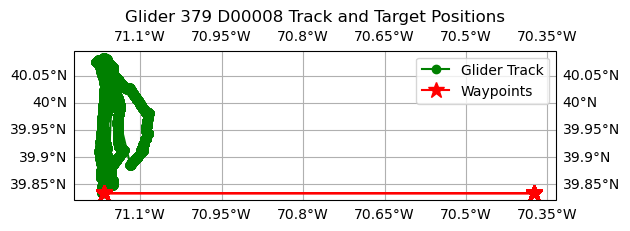

In [17]:
# Plot just the north transect
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import matplotlib.pyplot as plt

# Extract glider waypoints, filtering out invalid (0.0) entries
waypoint_lon = west_transect['waypoint_lon']
filtered_waypoint_lon = waypoint_lon.where(waypoint_lon != 0.0, drop=True)
waypoint_lat = west_transect['waypoint_lat']
filtered_waypoint_lat = waypoint_lat.where(waypoint_lat != 0.0, drop=True)

# Extract glider positions
track_lon = west_transect['glider_precise_lon']
track_lat = west_transect['glider_precise_lat']

# Get Pioneer NES mooring locations
# pioneer_moorings = moorings[moorings['mooring'].str.startswith('CP0')]
# pioneer_lat = pioneer_moorings['lat']
# pioneer_lon = pioneer_moorings['lon']

# Plot the glider track and waypoints
fig, ax = plt.subplots(subplot_kw={'projection': ccrs.PlateCarree()})
ax.set_title('Glider 379 D00008 Track and Target Positions')

ax.coastlines()
ax.add_feature(cfeature.BORDERS, linestyle=':')
ax.gridlines(draw_labels=True)

ax.plot(track_lon, track_lat, color='green', marker='o', label='Glider Track', transform=ccrs.PlateCarree())
ax.plot(filtered_waypoint_lon, filtered_waypoint_lat, color='red', marker='*', markersize=12, label='Waypoints', transform=ccrs.PlateCarree())

# Plot the mooring locations
# ax.plot(pioneer_lon, pioneer_lat, marker='x', markersize = 8, linestyle='None', color='blue', label='Mooring Location', transform=ccrs.PlateCarree())

ax.legend()
plt.tight_layout()
plt.show()

In [18]:
glider_new

<xarray.Dataset> Size: 3GB
Dimensions:                                    (time: 604054, bin: 30)
Coordinates:
    lon                                        (time) float64 5MB -70.6 ... -...
    depth                                      (time) float64 5MB 0.0 ... 0.0
    lat                                        (time) float64 5MB 40.05 ... 4...
  * bin                                        (bin) int32 120B 0 1 2 ... 28 29
  * time                                       (time) datetime64[ns] 5MB 2019...
Data variables: (12/75)
    corrected_echo_intensity_beam4             (time, bin) float64 145MB 56.1...
    num_cells                                  (time) float32 2MB 30.0 ... 30.0
    ensemble_number                            (time) float32 2MB 1.0 ... 159.0
    transducer_depth                           (time) float32 2MB 1.0 ... 1.0...
    corrected_echo_intensity_beam3             (time, bin) float64 145MB 72.5...
    corrected_echo_intensity_beam2             (time, bin) float64 145MB 63.4...
    ...                                         ...
    principal_direction                        (time) <U5 12MB 'West' ... 'West'
    profile_identifier                         (time) <U10 24MB 'T1_W_P0001' ...
    actual_direction                           (time) <U7 17MB 'Unknown' ... ...
    is_deviation                               (time) bool 604kB False ... False
    deviation_segment                          (time) int64 5MB 0 0 0 ... 0 0 0
    bearing_diff                               (time) float64 5MB nan ... 31.94
Attributes: (12/67)
    node:                               GL379
    comment:                            Data produced by the OOI M2M API and ...
    publisher_email:                    
    sourceUrl:                          http://oceanobservatories.org/
    collection_method:                  recovered_host
    stream:                             adcp_velocity_earth
    ...                                 ...
    geospatial_lat_units:               degrees_north
    geospatial_lat_resolution:          0.1
    geospatial_lon_min:                 -70.65249279445464
    geospatial_lon_max:                 -70.37325248678327
    geospatial_lon_units:               degrees_east
    geospatial_lon_resolution:          0.1

In [ ]:
np.unique(south_transect['principal_direction'])

### Warm Core Rings
Pull in the 2018 - 2023 warm core rings trajectory datasets


In [102]:
wcr = pd.read_csv("../data/WCR_2018_2023.csv")
wcr

,Name,Date of Formation,Lon at Formation,Lat at Formation,Area at Formation (km^2),Date of Demise,Lon at Demise,Lat at Demise,Area at Demise (km^2)
0,WE20180112G,1/12/18,-62.21,39.66,46764.72,1/19/18,-62.30,39.60,40938.95
1,WE20180112H,1/12/18,-62.23,41.37,6964.24,5/2/18,-64.74,42.03,11357.32
2,WE20180209I,2/9/18,-58.99,41.53,12395.45,3/30/18,-58.96,41.81,10752.60
3,WE20180404J,4/4/18,-59.56,40.42,45181.93,5/28/18,-62.31,41.37,14614.71
4,WE20180420K,4/20/18,-69.01,39.61,4771.91,6/25/18,-72.02,38.84,5606.73
...,...,...,...,...,...,...,...,...,...
149,WE20230830S,8/30/23,-55.68,41.07,20289.43,9/15/23,-55.44,41.29,19109.74
150,WE20230920T,9/20/23,-61.23,41.21,16107.31,10/11/23,-61.76,41.05,11053.90
151,WE20231006U,10/6/23,-57.50,41.87,33236.64,1/31/24,-62.51,40.59,13444.68
152,WE20231025V,10/25/23,-62.04,40.01,84059.91,11/17/23,-63.32,39.80,51496.07


In [ ]:
find_latitude_segment_crossings(

In [103]:
wcr[(wcr["Lat at Formation"] < 40.083332) & (wcr['Lat at Demise'] > 40.083332)]

,Name,Date of Formation,Lon at Formation,Lat at Formation,Area at Formation (km^2),Date of Demise,Lon at Demise,Lat at Demise,Area at Demise (km^2)
12,WE20180702U,7/2/18,-63.00,39.90,31326.21,8/15/18,-63.57,40.21,33508.90
97,WE20210811Z,8/11/21,-62.46,40.08,16008.06,9/1/21,-62.72,40.17,23377.54
144,WE20230705N,7/5/23,-63.53,39.30,16672.27,8/4/23,-63.28,40.29,16641.60


In [30]:
import xarray as xr
import pandas as pd

def decode_days_since_0000(time: xr.DataArray) -> xr.DataArray:
    """
    Convert 'days since 0000-01-01' time to datetime64 using pandas.
    """
    return xr.apply_ufunc(
        lambda x: pd.to_datetime(x - 719528, unit="D", origin="unix"),
        time,
        vectorize=True,
        dask="parallelized",
        output_dtypes=["datetime64[ns]"],
    )


In [26]:
single_ring = xr.open_dataset("../data/wcr/WE20210809Y.nc")
single_ring['y'

<xarray.Dataset> Size: 160B
Dimensions:  (y: 1, x: 5)
Dimensions without coordinates: y, x
Data variables:
    Lon      (y, x) float64 40B ...
    Lat      (y, x) float64 40B ...
    Area     (y, x) float64 40B ...
    Date     (y, x) float64 40B ...

In [28]:
single_ring.load()

<xarray.Dataset> Size: 160B
Dimensions:  (y: 1, x: 5)
Dimensions without coordinates: y, x
Data variables:
    Lon      (y, x) float64 40B -56.55 -56.76 -56.73 -56.76 -56.96
    Lat      (y, x) float64 40B 41.38 41.47 41.28 40.85 40.4
    Area     (y, x) float64 40B 4.005e+04 4.907e+04 ... 2.694e+04 1.567e+04
    Date     (y, x) float64 40B 7.384e+05 7.384e+05 ... 7.384e+05 7.384e+05

In [99]:
find_latitude_segment_crossings(single_ring["Date"].values.flatten(), single_ring['Lat'].values.flatten(), single_ring['Lon'].values.flatten())

[]

In [27]:
older_ring = xr.open_dataset("../data/wcr/WE20180209I.nc")
older_ring

<xarray.Dataset> Size: 224B
Dimensions:  (y: 1, x: 7)
Dimensions without coordinates: y, x
Data variables:
    Lon      (y, x) float64 56B ...
    Lat      (y, x) float64 56B ...
    Area     (y, x) float64 56B ...
    Date     (y, x) float64 56B ...

In [33]:
np.array(['WE20110411l']*len(older_ring['Date"])).reshape(older_ring["Date"].shape)

SyntaxError: unterminated string literal (detected at line 1) (4183745158.py, line 1)

In [38]:
older_ring.dims

FrozenMappingWarningOnValuesAccess({'y': 1, 'x': 7})

In [39]:
older_ring["ID"] = (older_ring.dims, np.tile(['WE20110411l'], older_ring["Date"].shape))
older_ring

<xarray.Dataset> Size: 532B
Dimensions:  (y: 1, x: 7)
Dimensions without coordinates: y, x
Data variables:
    Lon      (y, x) float64 56B -58.99 -59.07 -59.21 -59.36 -58.67 -58.93 -58.96
    Lat      (y, x) float64 56B 41.53 41.53 41.53 41.54 41.79 41.8 41.81
    Area     (y, x) float64 56B 1.24e+04 1.064e+04 ... 1.081e+04 1.075e+04
    Date     (y, x) float64 56B 7.371e+05 7.371e+05 ... 7.371e+05 7.371e+05
    ID       (y, x) <U11 308B 'WE20110411l' 'WE20110411l' ... 'WE20110411l'

In [94]:
files = os.listdir(traj_dir)
ring_ids = [f.split(".")[0] for f in files if f.endswith('.nc')]
datasets = []
for rid in ring_ids:
    ds = xr.open_dataset(traj_dir + rid + ".nc")
    ds["Date"] = decode_days_since_0000(ds["Date"])
    ds["ring"] = (ds.dims, np.tile([rid], ds["Date"].shape))
    data_dict = {}
    for var in ds.variables:
            data_dict[var] = ("ring", ds[var].values.flatten())
    # Now create 
    datasets.append(xr.Dataset(data_vars = data_dict))



In [100]:
results = dict()
for rid in ring_ids:
    ds = xr.open_dataset(traj_dir + rid + ".nc")
    ds["Date"] = decode_days_since_0000(ds["Date"])
    crossings = find_latitude_segment_crossings(
        ds["Date"].values.flatten(),
        ds["Lat"].values.flatten(),
        ds["Lon"].values.flatten()
    )
    if len(crossings) > 0:
        results[rid] = crossings
    

In [101]:
results

{}

In [93]:
xr.Dataset(
    data_vars = data_dict,
)


<xarray.Dataset> Size: 152B
Dimensions:  (ring: 2)
Coordinates:
  * ring     (ring) <U11 88B 'WE20150608M' 'WE20150608M'
Data variables:
    Lon      (ring) float64 16B -74.21 -74.57
    Lat      (ring) float64 16B 36.81 36.1
    Area     (ring) float64 16B 3.066e+03 3.656e+03
    Date     (ring) datetime64[ns] 16B 2015-06-09 2015-06-16

In [62]:
xr.concat(datasets[0:2], dim='ring')

ValueError: cannot reindex or align along dimension 'x' because of conflicting dimension sizes: {2, 20}

In [66]:
ds['Lon'].

AttributeError: 'DataArray' object has no attribute 'flatten'

In [43]:
traj_dir = "../data/wcr/"
wcr = None
for f in os.listdir(traj_dir):
    if not f.endswith('.nc'):
        continue
        
    if wcr is None:
        wcr = xr.open_dataset(traj_dir + f)
        wcr["Date"] = decode_days_since_0000(wcr["Date"])
        id = f.split(".")[0]
        wcr["ID"] = (wcr.dims, np.tile([id], wcr["Date"].shape))
    else:
        new_wcr = xr.open_dataset(traj_dir + f)
        new_wcr["Date"] = decode_days_since_0000(new_wcr["Date"])
        id = f.split(".")[0]
        new_wcr["ID"] = (new_wcr.dims, np.tile([id], new_wcr["Date"].shape))
        wcr = xr.concat([wcr, new_wcr], dim=wcr.dims)

ValueError: cannot reindex or align along dimension 'x' because of conflicting dimension sizes: {2, 20}

In [49]:
wcr.load()

<xarray.Dataset> Size: 152B
Dimensions:  (y: 1, x: 2)
Dimensions without coordinates: y, x
Data variables:
    Lon      (y, x) float64 16B -62.2 -62.2
    Lat      (y, x) float64 16B 39.55 39.59
    Area     (y, x) float64 16B 4.327e+03 4.012e+03
    Date     (y, x) datetime64[ns] 16B 2018-07-26 2018-08-02
    ID       (y, x) <U11 88B 'WE20180725W' 'WE20180725W'

In [136]:
# Figure of occupations at the FZ locations
from scipy.io import loadmat

mat_data = loadmat('../data/new_coastal2022.mat', squeeze_me=True, struct_as_record=True)

# Convert all data to a regular dict (excluding metadata)
data_dict = {key: mat_data[key].squeeze() for key in mat_data 
             if not key.startswith('__')}

In [144]:
test = xr.open_dataset("/home/jovyan/reedan88/ooicgsn_glider_dvl/data/gdac/FZ1/cp_339-20170116T2353-delayed.nc")
test

<xarray.Dataset> Size: 2GB
Dimensions:                                  (trajectory: 1, profile: 6936,
                                              obs: 6854198)
Coordinates:
  * trajectory                               (trajectory) object 8B 'cp_339-2...
    time                                     (profile) datetime64[ns] 55kB ...
    latitude                                 (profile) float64 55kB ...
    longitude                                (profile) float64 55kB ...
    lat_uv                                   (profile) float64 55kB ...
    lon_uv                                   (profile) float64 55kB ...
    time_uv                                  (profile) datetime64[ns] 55kB ...
    depth                                    (obs) float32 27MB ...
Dimensions without coordinates: profile, obs
Data variables: (12/57)
    wmo_id                                   (trajectory) object 8B ...
    profile_id                               (profile) float64 55kB ...
    u                                        (profile) float64 55kB ...
    v                                        (profile) float64 55kB ...
    trajectoryIndex                          (profile) int32 28kB ...
    rowSize                                  (profile) int32 28kB ...
    ...                                       ...
    qartod_temperature_spike_flag            (obs) float32 27MB ...
    radiation_wavelength                     (obs) float64 55MB ...
    roll                                     (obs) float64 55MB ...
    salinity                                 (obs) float32 27MB ...
    source_file                              (obs) object 55MB ...
    temperature                              (obs) float32 27MB ...
Attributes: (12/74)
    acknowledgment:                 Funding provided by the National Science ...
    cdm_data_type:                  TrajectoryProfile
    cdm_profile_variables:          time_uv,lat_uv,lon_uv,u,v,profile_id,time...
    cdm_trajectory_variables:       trajectory,wmo_id
    comment:                        The oxygen optode was disabled for this d...
    contributor_name:               Al Plueddemann, Derek Buffitt, Peter Bric...
    ...                             ...
    time_coverage_resolution:       PT01.020598S
    time_coverage_start:            2017-01-17T00:02:52Z
    title:                          cp_339-20170116T2353-delayed
    uuid:                           cc318a55-412d-226e-3dff-43012b315fc7
    version:                        2.0
    Westernmost_Easting:            -71.749142877342

In [160]:
from ooinet import M2M

In [167]:
M2M.get_deployments(refdes="CP05MOAS-GL336-03-CTDGVM000")

,deploymentNumber,uid,assetId,latitude,longitude,depth,deployStart,deployEnd,deployCruise,recoverCruise
0,1,CGINS-CTDGVM-09030,3910,40.02043,-70.38543,1000.0,2015-01-11 20:57:00,2015-03-27 21:18:00,SI20150110,MM20150327
1,2,CGINS-CTDGVM-09030,3910,39.84253,-70.34048,1000.0,2016-08-09 13:54:00,2016-08-18 12:45:00,CT20160808,TS20160818
2,3,CGINS-CTDGVM-09030,3910,40.08542,-70.37783,1000.0,2016-10-11 00:58:00,2016-12-19 22:00:00,AR8,TS20161219
3,4,CGINS-CTDGVM-09030,3910,39.91815,-70.39952,1000.0,2017-01-16 12:54:00,2017-04-19 13:15:16,WJ20170115,SI20170418
4,5,CGINS-CTDGVM-09030,3910,39.92003,-70.86755,1000.0,2017-08-17 11:59:00,2017-10-28 23:52:00,WJ20170815,AR24
5,6,CGINS-CTDGVM-09030,3910,39.85958,-70.38218,1000.0,2018-01-27 16:20:00,2018-04-03 11:50:00,SI20180126,STD20180403
6,7,CGINS-CTDGVM-09362,1654,39.94883,-70.67285,1000.0,2018-07-24 14:33:00,2018-10-25 23:38:00,CT20180724,AR31
7,8,CGINS-CTDGVM-09060,3938,39.95807,-71.00037,1000.0,2019-04-08 00:14:00,2019-04-08 10:56:00,AR34,AR34
8,9,CGINS-CTDGVM-09060,3938,40.03682,-70.78160,1000.0,2019-05-16 23:37:11,2019-07-28 23:59:59,TS20190516,UNRECOVERED


In [159]:
test["time"].min().values, test["time"].max().values

(np.datetime64('2017-01-17T00:02:52.110840064'),
 np.datetime64('2017-04-19T09:30:38.310164992'))

In [178]:
test['ctd_timestamp'].dropna(dim='obs').min() < np.datetime64('2013-01-01')

<xarray.DataArray 'ctd_timestamp' ()> Size: 1B
array(True)

In [ ]:
{
                        "time": t_cross,
                        "lon": lon_cross,
                        "direction": direction,
                        "index": i,
                    }

In [202]:
FZ1_dir = "/home/jovyan/reedan88/ooicgsn_glider_dvl/data/gdac/FZ2/"
results = []
for n, file in enumerate(os.listdir(FZ1_dir)):
    if not file.endswith(".nc"):
        continue
    ds = xr.open_dataset(FZ1_dir + file)
    # Get first and last timestamps
    times = ds['ctd_timestamp'].load().dropna(dim='obs').values
    times = times[times > np.datetime64('2013-01-01')]
    min_t = times.min()
    max_t = times.max()
    name = file.split("-")[0].upper()
    results.append((name, min_t, max_t, n))

In [203]:
FZ2 = results

In [204]:
FZ1

[('CP_380',
  np.datetime64('2021-12-15T08:50:44.159430144'),
  np.datetime64('2022-02-19T19:05:12.928529920'),
  0),
 ('CP_379',
  np.datetime64('2020-08-19T17:50:54.892339968'),
  np.datetime64('2020-11-04T19:31:48.026760192'),
  1),
 ('CP_379',
  np.datetime64('2019-09-27T12:28:43.059910144'),
  np.datetime64('2019-11-18T20:30:27.534909952'),
  2),
 ('CP_376',
  np.datetime64('2017-10-28T22:02:01.808569856'),
  np.datetime64('2018-01-27T18:00:44.484770048'),
  4),
 ('CP_336',
  np.datetime64('2018-07-24T14:38:27.639130112'),
  np.datetime64('2018-10-25T01:40:29.312679936'),
  5),
 ('CP_339',
  np.datetime64('2017-01-16T23:40:34.045870080'),
  np.datetime64('2017-04-19T09:38:17.104320000'),
  6),
 ('CP_387',
  np.datetime64('2019-04-08T01:42:47.794680064'),
  np.datetime64('2019-06-18T09:42:19.432559872'),
  7),
 ('CP_380',
  np.datetime64('2015-07-23T22:14:23.551820032'),
  np.datetime64('2015-10-14T23:46:40.267970048'),
  8),
 ('CP_380',
  np.datetime64('2019-12-12T22:41:53.1371200

In [205]:
FZ2

[('CP_374',
  np.datetime64('2015-05-09T13:24:29.686439936'),
  np.datetime64('2016-08-09T07:00:20.550110208'),
  0),
 ('CP_336',
  np.datetime64('2019-04-08T00:20:40.423379968'),
  np.datetime64('2019-04-08T10:24:16.351779840'),
  1),
 ('CP_380',
  np.datetime64('2014-10-07T01:22:46.095439872'),
  np.datetime64('2015-01-04T11:16:12.005229824'),
  2),
 ('CP_913',
  np.datetime64('2022-09-20T20:32:34.675000064'),
  np.datetime64('2022-11-10T18:47:48.910000128'),
  3),
 ('CP_388',
  np.datetime64('2022-01-04T20:50:49.757479936'),
  np.datetime64('2022-02-22T07:24:59.172280064'),
  4),
 ('CP_376',
  np.datetime64('2019-06-18T23:26:26.800640000'),
  np.datetime64('2019-06-26T18:14:21.898649856'),
  5),
 ('CP_376',
  np.datetime64('2016-01-21T14:38:41.935090176'),
  np.datetime64('2016-01-28T21:52:10.469250048'),
  6),
 ('CP_389',
  np.datetime64('2018-07-24T16:12:00.919770112'),
  np.datetime64('2018-10-19T13:08:43.302619904'),
  7),
 ('CP_335',
  np.datetime64('2016-05-27T22:58:39.8060600

In [211]:
end - start.

np.timedelta64(5739268769099776,'ns')

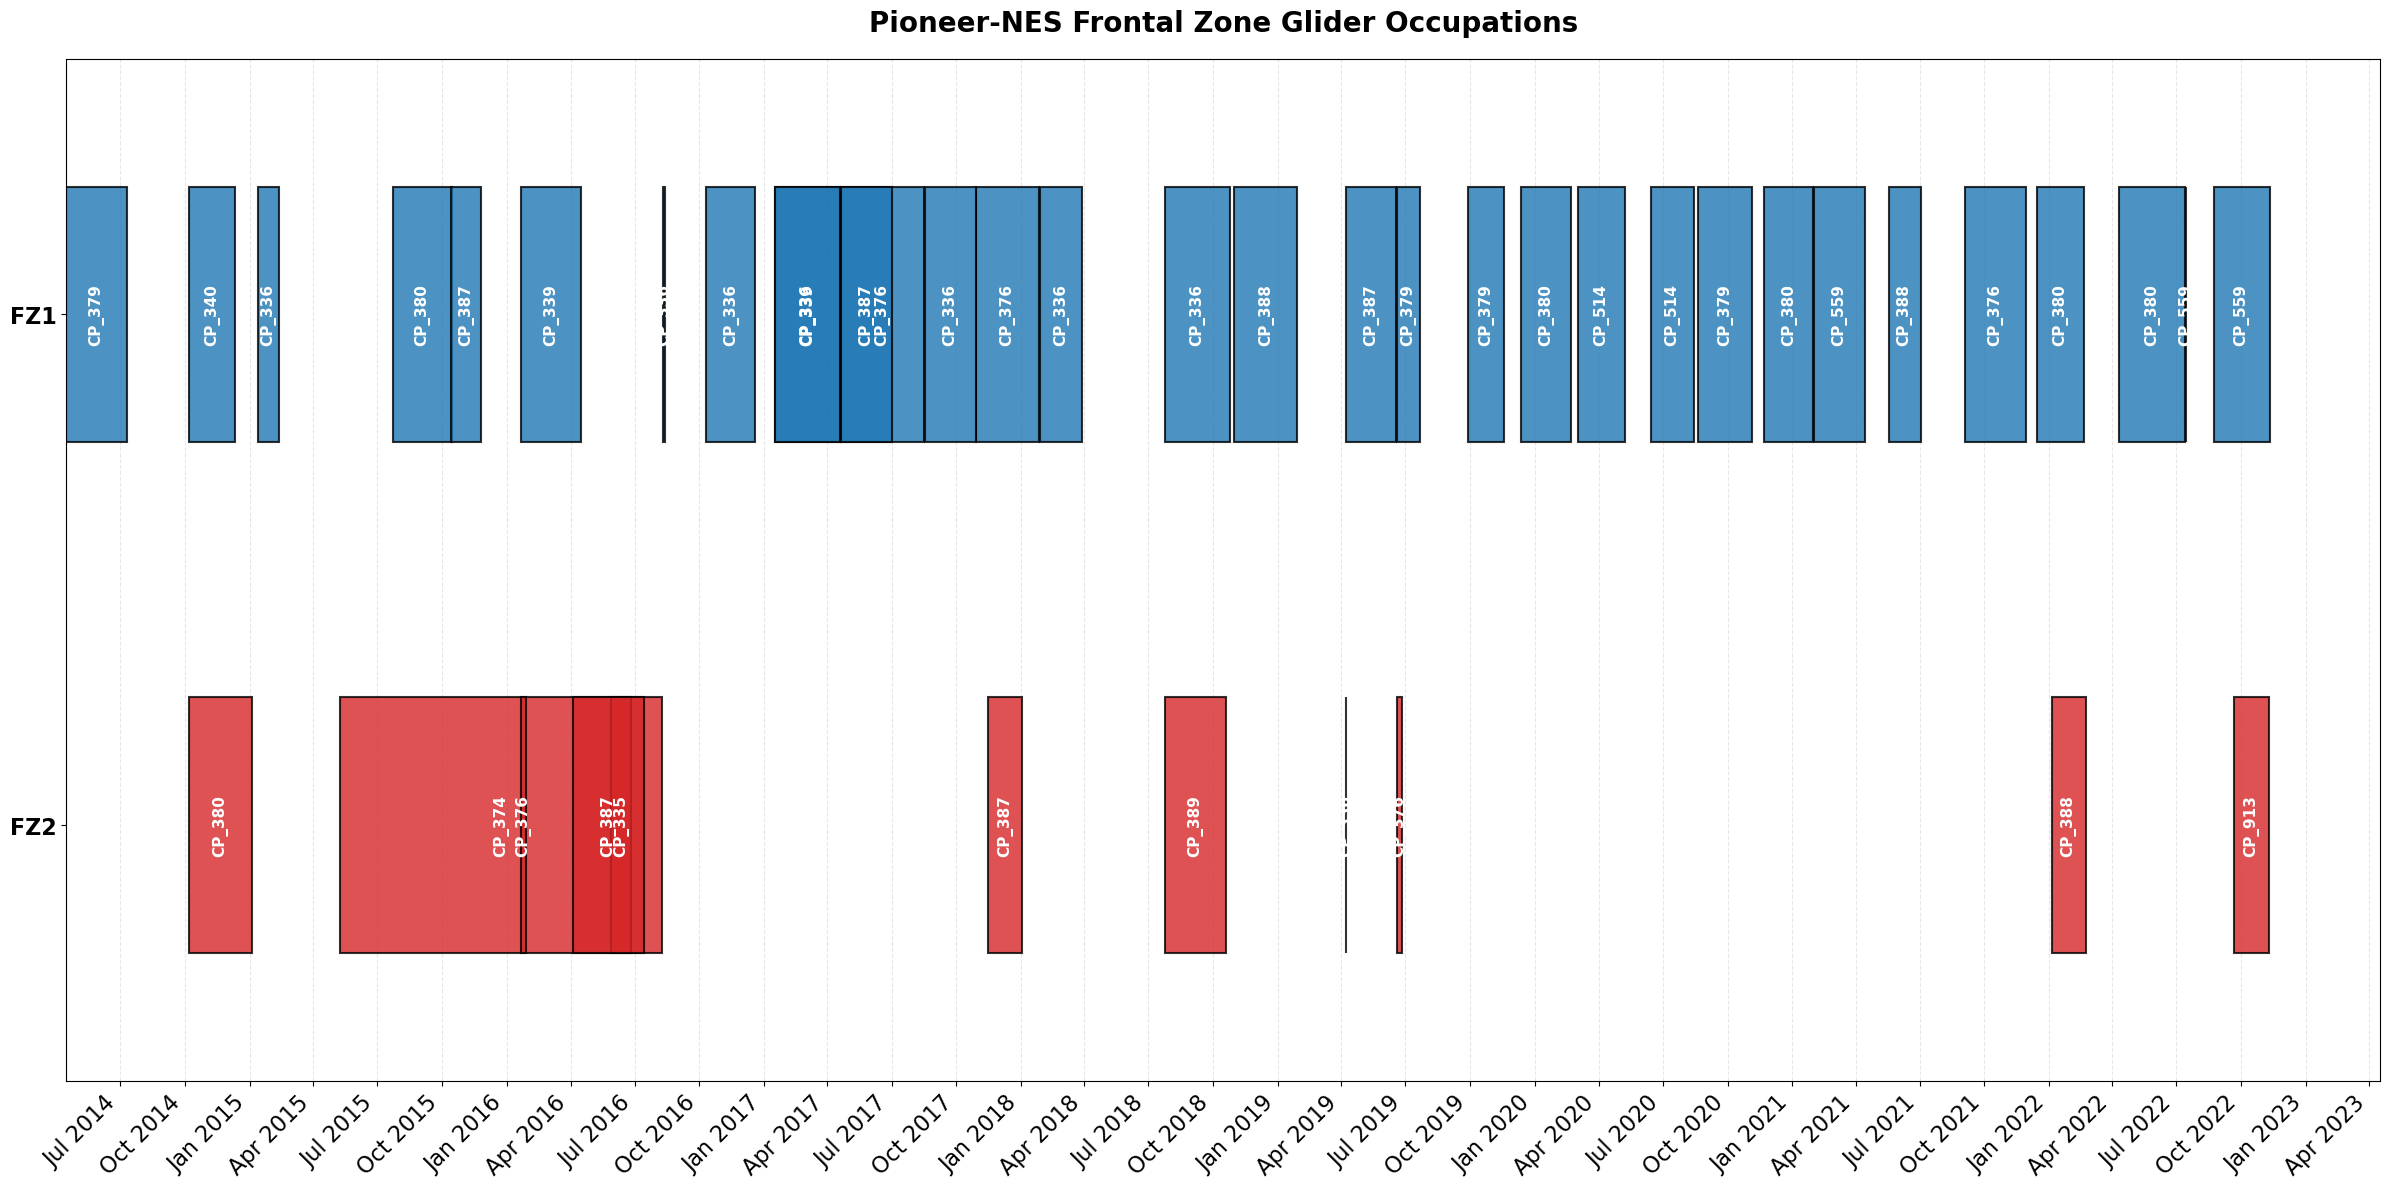

In [232]:
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from datetime import datetime

# Example deployment data
# Format: (glider_name, start_date, end_date)
deployments = [
    ('CP338', datetime(2024, 1, 15), datetime(2024, 3, 20)),
    ('CP412', datetime(2024, 3, 25), datetime(2024, 6, 10)),
    ('CP338', datetime(2024, 6, 15), datetime(2024, 8, 30)),
    ('CP501', datetime(2024, 9, 5), datetime(2024, 11, 15)),
    ('CP412', datetime(2024, 11, 20), datetime(2025, 1, 10)),
]

# Create figure
fig, ax = plt.subplots(figsize=(24, 12))

# Plot each deployment on the same horizontal line (y=0)
for i, (glider, start, end, _) in enumerate(FZ1):
    duration = (end - start).astype('timedelta64[D]').astype(int)
    ax.barh(0, duration, left=mdates.date2num(start), height=0.5, 
            align='center', alpha=0.8, edgecolor='black', linewidth=1.5,
           facecolor='tab:blue')
    
    # Add glider name label in the center of the bar
    mid_point = mdates.date2num(start) + duration / 2
    ax.text(mid_point, 0, glider, ha='center', va='center', 
            fontweight='bold', fontsize=11, color='white', rotation=90)

for i, (glider, start, end, _) in enumerate(FZ2):
    duration = (end - start).astype('timedelta64[D]').astype(int)
    ax.barh(1, duration, left=mdates.date2num(start), height=0.5, 
            align='center', alpha=0.8, edgecolor='black', linewidth=1.5,
           facecolor='tab:red')
    
    # Add glider name label in the center of the bar
    mid_point = mdates.date2num(start) + duration / 2
    ax.text(mid_point, 1, glider, ha='center', va='center', 
            fontweight='bold', fontsize=11, color='white', rotation=90)

# Format x-axis as dates
ax.xaxis_date()
ax.xaxis.set_major_formatter(mdates.DateFormatter('%b %Y'))
ax.xaxis.set_major_locator(mdates.MonthLocator(interval=3))
plt.xticks(rotation=45, ha='right', fontsize=16)

# Labels and title
#ax.set_xlabel('Date', fontsize=12, fontweight='bold')
ax.set_title('Pioneer-NES Frontal Zone Glider Occupations', 
             fontsize=20, fontweight='bold', pad=20)

# Set y-axis (hide it since all on same line)
# Set y-axis
ax.set_yticks(range(len(['FZ1','FZ2'])))
ax.set_yticklabels(['FZ1','FZ2'], fontsize=16, fontweight='bold')
ax.set_ylim(-0.5, len(['FZ1','FZ2']) - 0.5)
ax.invert_yaxis()  # Top location at top

# Grid
ax.grid(axis='x', alpha=0.3, linestyle='--')
ax.set_axisbelow(True)

# Adjust layout
plt.tight_layout()
plt.show()

In [233]:
fig.savefig("../../ooicgsn_glider_dvl/results/figures/glider_occupations.png", facecolor='white', transparent=False, bbox_inches='tight')

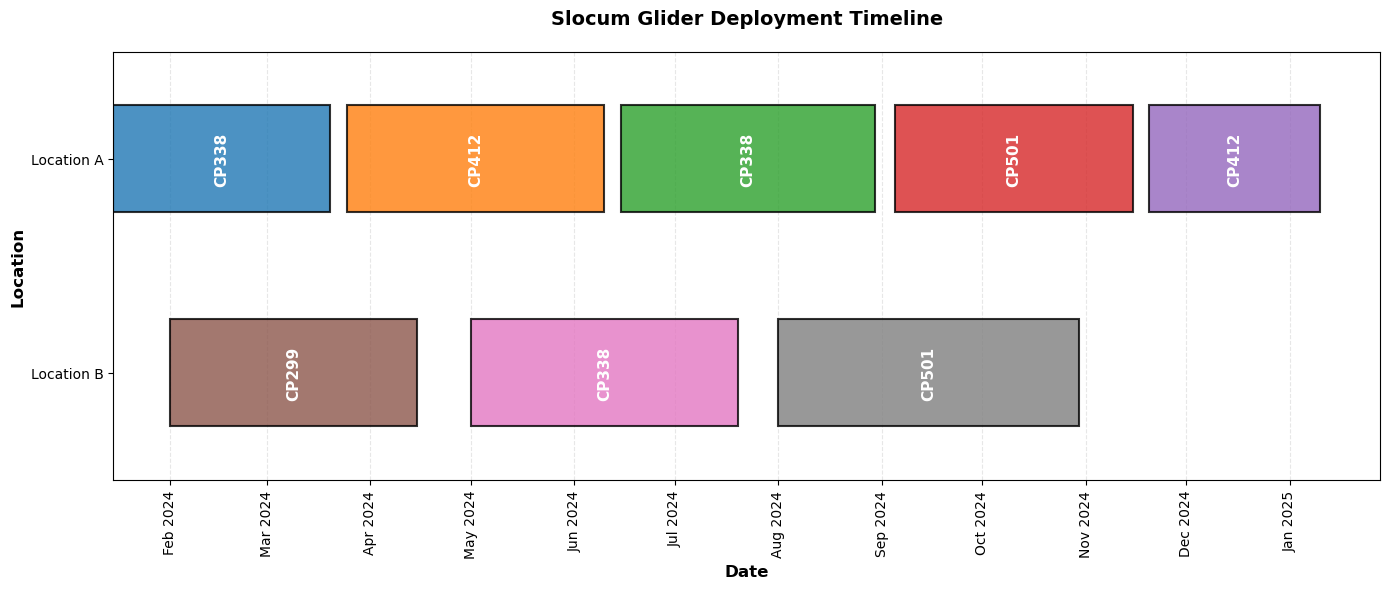

In [223]:
deployments = [
    ('Location A', 'CP338', datetime(2024, 1, 15), datetime(2024, 3, 20)),
    ('Location A', 'CP412', datetime(2024, 3, 25), datetime(2024, 6, 10)),
    ('Location A', 'CP338', datetime(2024, 6, 15), datetime(2024, 8, 30)),
    ('Location A', 'CP501', datetime(2024, 9, 5), datetime(2024, 11, 15)),
    ('Location A', 'CP412', datetime(2024, 11, 20), datetime(2025, 1, 10)),
    ('Location B', 'CP299', datetime(2024, 2, 1), datetime(2024, 4, 15)),
    ('Location B', 'CP338', datetime(2024, 5, 1), datetime(2024, 7, 20)),
    ('Location B', 'CP501', datetime(2024, 8, 1), datetime(2024, 10, 30)),
]

# Group deployments by location
locations = {}
for loc, glider, start, end in deployments:
    if loc not in locations:
        locations[loc] = []
    locations[loc].append((glider, start, end))

# Create figure
fig, ax = plt.subplots(figsize=(14, 6))

# Plot each location on a separate row
location_names = list(locations.keys())
for loc_idx, loc_name in enumerate(location_names):
    for glider, start, end in locations[loc_name]:
        duration = (end - start).days
        ax.barh(loc_idx, duration, left=mdates.date2num(start), height=0.5, 
                align='center', alpha=0.8, edgecolor='black', linewidth=1.5)
        
        # Add glider name label in the center of the bar
        mid_point = mdates.date2num(start) + duration / 2
        ax.text(mid_point, loc_idx, glider, ha='center', va='center', 
                fontweight='bold', fontsize=11, color='white', rotation=90)

# Format x-axis as dates
ax.xaxis_date()
ax.xaxis.set_major_formatter(mdates.DateFormatter('%b %Y'))
ax.xaxis.set_major_locator(mdates.MonthLocator(interval=1))
plt.xticks(rotation=90, ha='center')

# Labels and title
ax.set_xlabel('Date', fontsize=12, fontweight='bold')
ax.set_ylabel('Location', fontsize=12, fontweight='bold')
ax.set_title('Slocum Glider Deployment Timeline', 
             fontsize=14, fontweight='bold', pad=20)

# Set y-axis
ax.set_yticks(range(len(location_names)))
ax.set_yticklabels(location_names)
ax.set_ylim(-0.5, len(location_names) - 0.5)
ax.invert_yaxis()  # Top location at top

# Grid
ax.grid(axis='x', alpha=0.3, linestyle='--')
ax.set_axisbelow(True)

# Adjust layout
plt.tight_layout()
plt.show()

In [225]:
locations

{'Location A': [('CP338',
   datetime.datetime(2024, 1, 15, 0, 0),
   datetime.datetime(2024, 3, 20, 0, 0)),
  ('CP412',
   datetime.datetime(2024, 3, 25, 0, 0),
   datetime.datetime(2024, 6, 10, 0, 0)),
  ('CP338',
   datetime.datetime(2024, 6, 15, 0, 0),
   datetime.datetime(2024, 8, 30, 0, 0)),
  ('CP501',
   datetime.datetime(2024, 9, 5, 0, 0),
   datetime.datetime(2024, 11, 15, 0, 0)),
  ('CP412',
   datetime.datetime(2024, 11, 20, 0, 0),
   datetime.datetime(2025, 1, 10, 0, 0))],
 'Location B': [('CP299',
   datetime.datetime(2024, 2, 1, 0, 0),
   datetime.datetime(2024, 4, 15, 0, 0)),
  ('CP338',
   datetime.datetime(2024, 5, 1, 0, 0),
   datetime.datetime(2024, 7, 20, 0, 0)),
  ('CP501',
   datetime.datetime(2024, 8, 1, 0, 0),
   datetime.datetime(2024, 10, 30, 0, 0))]}

In [224]:
loc_idx

1

## *Plotting the track of Glider 379*
Plotting the track:
- ensures that the glider stuck to the preprogrammed waypoints
- shows us which moorings the glider passes by for future comparison

In [ ]:
# Load in mooring data
moorings = pd.read_csv("../data/external/mooring_locations.csv")

In [ ]:
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import matplotlib.pyplot as plt

# Extract glider waypoints, filtering out invalid (0.0) entries
waypoint_lon = glider['waypoint_lon']
filtered_waypoint_lon = waypoint_lon.where(waypoint_lon != 0.0, drop=True)
waypoint_lat = glider['waypoint_lat']
filtered_waypoint_lat = waypoint_lat.where(waypoint_lat != 0.0, drop=True)

# Extract glider positions
track_lon = glider['glider_precise_lon']
track_lat = glider['glider_precise_lat']

# Get Pioneer NES mooring locations
pioneer_moorings = moorings[moorings['mooring'].str.startswith('CP0')]
pioneer_lat = pioneer_moorings['lat']
pioneer_lon = pioneer_moorings['lon']

# Plot the glider track and waypoints
fig, ax = plt.subplots(subplot_kw={'projection': ccrs.PlateCarree()})
ax.set_title('Glider 379 D00008 Track and Target Positions')

ax.coastlines()
ax.add_feature(cfeature.BORDERS, linestyle=':')
ax.gridlines(draw_labels=True)

ax.plot(track_lon, track_lat, color='green', marker='o', label='Glider Track', transform=ccrs.PlateCarree())
ax.plot(filtered_waypoint_lon, filtered_waypoint_lat, color='red', marker='*', markersize=12, label='Waypoints', transform=ccrs.PlateCarree())

# Plot the mooring locations
ax.plot(pioneer_lon, pioneer_lat, marker='x', markersize = 8, linestyle='None', color='blue', label='Mooring Location', transform=ccrs.PlateCarree())

ax.legend()
plt.tight_layout()
plt.show()

In [ ]:
lat = waypoint_lat.values
lon = waypoint_lon.values
np.unique(np.column_stack([lat, lon]), axis=0)

In [ ]:
check = list(zip(waypoint_lat, waypoint_lon))
check

## *Subsetting the track*
Our analysis will focus on the northern portion of the track.

In [ ]:
# Subset the data based on a latitude threshold
target_lat = 40.09
tolerance = 0.03

mask = abs(glider['glider_precise_lat'] - target_lat) <= tolerance
filtered_track = {
    var: glider[var].where(mask, drop=True)
    for var in ['glider_precise_lon', 'glider_precise_lat']
}

# Plot the glider track and waypoints
fig, ax = plt.subplots(subplot_kw={'projection': ccrs.PlateCarree()})
ax.set_title('Glider 379 D00008 Subsetted Track and Target Positions')

ax.coastlines()
ax.add_feature(cfeature.BORDERS, linestyle=':')
ax.gridlines(draw_labels=True)

ax.plot(filtered_track['glider_precise_lon'], filtered_track['glider_precise_lat'], color='green', marker='o', label='Northern Portion', transform=ccrs.PlateCarree())
ax.plot(filtered_waypoint_lon, filtered_waypoint_lat, color='red', marker='*', markersize=12, label='Waypoints', transform=ccrs.PlateCarree())

ax.plot(pioneer_lon, pioneer_lat, marker='x', markersize = 8, linestyle='None', color='blue', label='Mooring Location', transform=ccrs.PlateCarree())

ax.legend()
plt.tight_layout()
plt.show()

## *Getting one transect and one dive*
Throughout the northern portion, the glider makes multiple east–west passes. We define each completed pass as a transect.

We will focus on one of these transects (occurring from 2019-10-05 to 2019-10-08), which is composed of numerous dives. We will also analyze a single dive from this transect. 

In [ ]:
import matplotlib.dates as mdates

# Subset the data by transect date
transect_start = '2019-10-05T02:42:00'
transect_end = '2019-10-08T01:47:00'
transect_subset = glider.sel(time=slice(transect_start, transect_end))
gdac_subset = gdac.sel(time=slice(transect_start, transect_end))
adcp_subset = adcp.sel(time=slice(transect_start, transect_end))

# Extract time and pressure values for transect
transect_times = pd.to_datetime(transect_subset['time'].values).to_pydatetime()
transect_pressure = transect_subset['non_zero_pressure'].values
gdac_times = pd.to_datetime(gdac_subset['time'].values).to_pydatetime()
adcp_times = pd.to_datetime(adcp_subset['time'].values).to_pydatetime()
gdac_pressure = gdac_subset['pressure'].values
adcp_pressure = adcp_subset['non_zero_pressure'].values

# Subset the data by dive date
dive_start = '2019-10-07T03:05:00'
dive_end = '2019-10-07T08:35:00'
dive_subset = glider.sel(time=slice(dive_start, dive_end))
gdac_dive_subset = gdac.sel(time=slice(dive_start, dive_end))
adcp_dive_subset = adcp.sel(time=slice(dive_start, dive_end))

# Extract time and pressure values for dive
dive_times = pd.to_datetime(dive_subset['time'].values).to_pydatetime()
dive_pressure = dive_subset['non_zero_pressure'].values
gdac_dive_times = pd.to_datetime(gdac_dive_subset['time'].values).to_pydatetime()
adcp_dive_times = pd.to_datetime(adcp_dive_subset['time'].values).to_pydatetime()
gdac_dive_pressure = gdac_dive_subset['pressure'].values
adcp_dive_pressure = adcp_dive_subset['non_zero_pressure'].values

# Plotting both the transect and dive data
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 8))

# Transect
c1 = ax1.plot(transect_times, transect_pressure)
ca = ax1.plot(gdac_times, gdac_pressure)
ck = ax1.plot(adcp_times, adcp_pressure)
ax1.set_ylabel('Pressure (dbar)')
ax1.set_xlabel('Time')
ax1.set_title('Pressure vs. Time (Full Transect)')
ax1.invert_yaxis()
ax1.xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m-%d\n%H:%M'))
plt.setp(ax1.get_xticklabels(), rotation=45, ha='right')
ax1.grid(True)

# Dive
c2 = ax2.plot(dive_times, dive_pressure, marker = 'o', markersize = 8)
cb = ax2.plot(gdac_dive_times, gdac_dive_pressure, marker='.')
cn = ax2.plot(adcp_dive_times, adcp_dive_pressure, marker='*')
ax2.set_xlabel('Time')
ax2.set_ylabel('Pressure (dbar)')
ax2.set_title('Pressure vs. Time (Single Dive)')
ax2.invert_yaxis()
ax2.xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m-%d\n%H:%M'))
plt.setp(ax2.get_xticklabels(), rotation=45, ha='right')
ax2.grid(True)

plt.tight_layout()
plt.show()

#### Calculate the distance between successive dives
* DVL
* Hydrography

In [ ]:
import math

def haversine(lat1, lon1, lat2, lon2):
    """
    Calculate great-circle distance between two points on Earth (in km).
    """
    R = 6371.0  # Earth radius in kilometers

    # Convert degrees → radians
    lat1, lon1, lat2, lon2 = map(math.radians, [lat1, lon1, lat2, lon2])

    # Haversine formula
    dlat = lat2 - lat1
    dlon = lon2 - lon1
    a = math.sin(dlat / 2)**2 + math.cos(lat1) * math.cos(lat2) * math.sin(dlon / 2)**2
    c = 2 * math.atan2(math.sqrt(a), math.sqrt(1 - a))
    return R * c  # distance in km

In [ ]:
# Grab the gdac profiles
# Subset the data by transect date
transect_start = '2019-10-05T02:42:00'
transect_end = '2019-10-08T01:47:00'
gdac_subset = gdac.sel(time=slice(transect_start, transect_end))

# Get the min and max time values
min_t = transect_subset['time'].min().values
max_t = transect_subset['time'].max().values
transect_subset.sel(time=min_t)[['lat','lon']].load()

In [ ]:
profiles = glider[['profile_id']]
profiles['lat_var'] = profiles['lat']
profiles['lon_var'] = profiles['lon']
profiles['time_var'] = profiles['time']

# Now groupby profile_id and get the mean lat/lon/depth
dvl_lat_lon = profiles.groupby('profile_id').mean()

# Calculate the distances
distances = []
pids = dvl_lat_lon['profile_id'].values
for n, pid in enumerate(pids):
    if pid == np.max(pid):
        break
    lat1 = dvl_lat_lon['lat_var'].sel(profile_id=pid)
    lon1 = dvl_lat_lon['lon_var'].sel(profile_id=pid)
    lat2 = dvl_lat_lon['lat_var'].sel(profile_id=pid+1)
    lon2 = dvl_lat_lon['lon_var'].sel(profile_id=pid+1)
    d = haversine(lat1, lon1, lat2, lon2)
    distances.append(d)

## *Investigating Quality Control Parameters*
Having extracted a single dive from the dataset, we can plot correlation magnitudes and quality control flags for various points within the dive. This will enable us to establish a quality threshold for subsequent analysis.

In [ ]:
# Selecting a data point early in the single dive above
target_time1 = '2019-10-07T03:13:00'       
dive_profile1 = dive_subset.sel(time=target_time1, method='nearest')

# Selecting a data point later in the single dive above
target_time2 = '2019-10-07T03:21:00'
dive_profile2 = dive_subset.sel(time=target_time2, method='nearest')

# Extracting correlation magnitude beam and QC vendor flag for these points
bins1 = dive_profile1['bin'].values
depth1 = int(dive_profile1['non_zero_pressure'].values.round())
correlation1 = dive_profile1['correlation_magnitude_beam2'].values
QC1 = dive_profile1['vendor_qc_flag'].values

bins2 = dive_profile2['bin'].values
depth2 = int(dive_profile2['non_zero_pressure'].values.round())
correlation2 = dive_profile2['correlation_magnitude_beam2'].values
QC2 = dive_profile2['vendor_qc_flag'].values

# Plotting these parameters for each bin
fig, ((ax1, ax2), (ax3, ax4)) = plt.subplots(2, 2, figsize=(10, 8))

c1 = ax1.scatter(correlation1, bins1, color='green')
ax1.set_ylabel('Bins')
ax1.set_xlabel('Correlation Magnitude Intensity')
ax1.set_title('Correlation Magnitude Earlier in Dive (~{}m)'.format(depth1))
ax1.invert_yaxis()
ax1.grid(True)

c2 = ax2.scatter(QC1, bins1, color='red')
ax2.set_xlabel('Quality Vendor Flag')
ax2.set_ylabel('Bins')
ax2.set_title('QC Flag Earlier in Dive (~{}m)'.format(depth1))
ax2.invert_yaxis()
ax2.grid(True)

c3 = ax3.scatter(correlation2, bins2, color='green')
ax3.set_ylabel('Bins')
ax3.set_xlabel('Correlation Magnitude Intensity')
ax3.set_title('Correlation Magnitude Later in Dive (~{}m)'.format(depth2))
ax3.invert_yaxis()
ax3.grid(True)

c4 = ax4.scatter(QC2, bins2, color='red')
ax4.set_xlabel('Quality Vendor Flag')
ax4.set_ylabel('Bins')
ax4.set_title('QC Flag Later in Dive (~{}m)'.format(depth2))
ax4.invert_yaxis()
ax4.grid(True)

plt.tight_layout()
plt.show()

Correlation magnitude intensities below 50 or 60 dB are indicative of bad data. QC vendor flags of 4 are indicative of bad data, flags of 3 are suspect, and flags of 1 indicate good data.

These graphs show that
- Correlation magnitude intensities drop around the same bin as the QC flag goes to 4
- Less good data is available later in dives

From these graphs, we determined our quality control threshold: <ins>*masking any data with a QC vendor flag of 4*</ins>

## *Applying the QC Mask to the Velocity Data*
Now that we established our quality threshold, we want to mask out any velocity measurements associated with bad data.

To do so, we would need to copy our original dataset and apply the mask.

In [ ]:
# Create mask based on QC flag
qc_mask = glider['vendor_qc_flag'] !=4

# Apply mask to northward and eastward velocities
NV_clean_nan = glider['northward_seawater_velocity'].where(qc_mask)
EV_clean_nan = glider['eastward_seawater_velocity'].where(qc_mask)

# Copy original dataset, filtering out bad velocity data
clean_velocities = glider.copy()

clean_velocities['northward_seawater_velocity'] = NV_clean_nan
clean_velocities['eastward_seawater_velocity'] = EV_clean_nan

# # Create a new, "clean" dataset
# clean_velocities.to_netcdf(
#     f"../data/processed/{glider_name}.deployment{dep_str}.clean_velocities.nc",
#     format="NETCDF4",
#     engine="netcdf4"
# )

In [ ]:
clean_velocities

## *Creating Depth-Averaged Velocity Profiles*
With our quality-controlled dataset, we can now create velocity profiles from the glider.

This is a multi-step process which includes:
- Ploting good velocity measurements over dives and transects (chosing dive nearest to Pioneer NES mooring CP02PMCO for eventual comparison)
- Grouping data into bins of equal depth
- Calculating the means and standard deviations in the bins
- Plotting the velocities against depth

In [ ]:
# Start with the dive subset

In [ ]:
# Get a single dive
profile = 119
dive_subset = clean_velocities.where(clean_velocities.profile_id == profile, drop=True)

# Plot a single dive
fig, (ax0, ax1) = plt.subplots(nrows=1, ncols=2)

ax0.plot(dive_subset['eastward_seawater_velocity'], dive_subset['bin_depths'], marker='.', linestyle='')
ax0.grid()
ax0.invert_yaxis()

ax1.plot(dive_subset['northward_seawater_velocity'], dive_subset['bin_depths'], marker='.', linestyle='')
ax1.grid()
ax1.invert_yaxis()

In [ ]:
adcp['time'].diff(dim='time')/1E9

In [ ]:
glider.where(glider.profile_id == 234, drop=True)

In [ ]:
df = dive_subset[['eastward_seawater_velocity','northward_seawater_velocity','bin_depths']].to_dataframe().groupby('bin_depths').mean()

In [ ]:
import pandas as pd
import numpy as np
from scipy.signal import butter, filtfilt, welch
import matplotlib.pyplot as plt

# Load dataset
# df = pd.read_csv("low_pass_filter_dataset.csv")

# Sampling parameters
dt = 2.0          # seconds between samples
fs = 1 / dt       # sampling frequency (Hz)
order = 4         # Butterworth filter order

# Helper: compute automatic cutoff
def estimate_cutoff(series, fs, power_fraction=0.95):
    """Estimate cutoff frequency where cumulative PSD reaches given fraction of total power."""
    series = series.interpolate(limit_direction='both').to_numpy()
    f, Pxx = welch(series, fs=fs, nperseg=min(256, len(series)//2))
    cumulative_power = np.cumsum(Pxx)
    cumulative_power /= cumulative_power[-1]  # normalize to 1
    cutoff_idx = np.argmax(cumulative_power >= power_fraction)
    cutoff_freq = f[cutoff_idx]
    return cutoff_freq, f, Pxx, cumulative_power

# Estimate cutoff for eastward and northward components
cut_e, f_e, Pxx_e, cum_e = estimate_cutoff(df['eastward_seawater_velocity'], fs)
cut_n, f_n, Pxx_n, cum_n = estimate_cutoff(df['northward_seawater_velocity'], fs)

# Choose overall cutoff as mean of the two
cutoff = np.mean([cut_e, cut_n])
print(f"Estimated cutoff frequency: {cutoff:.4f} Hz")

# Design low-pass Butterworth filter
nyquist = 0.5 * fs
normal_cutoff = min(cutoff / nyquist, 0.99)
b, a = butter(order, normal_cutoff, btype='low', analog=False)

# Apply filter
def lowpass_filter(series):
    series = series.interpolate(limit_direction='both')
    return filtfilt(b, a, series)

df['eastward_filtered'] = lowpass_filter(df['eastward_seawater_velocity'])
df['northward_filtered'] = lowpass_filter(df['northward_seawater_velocity'])

# Plot PSD and cumulative power
plt.figure(figsize=(10, 5))
plt.semilogy(f_e, Pxx_e, label='Eastward PSD')
plt.semilogy(f_n, Pxx_n, label='Northward PSD')
plt.axvline(cutoff, color='r', linestyle='--', label=f'Cutoff = {cutoff:.3f} Hz')
plt.xlabel('Frequency (Hz)')
plt.ylabel('Power Spectral Density')
plt.legend()
plt.title('Power Spectral Density and Cutoff')
plt.tight_layout()
plt.show()

# Plot filtered vs. raw
plt.figure(figsize=(12, 6))
plt.subplot(2, 1, 1)
plt.plot(df['eastward_seawater_velocity'], label='Raw', alpha=0.5)
plt.plot(df['eastward_filtered'], label='Filtered', linewidth=2)
plt.title('Eastward Velocity')
plt.legend()

plt.subplot(2, 1, 2)
plt.plot(df['northward_seawater_velocity'], label='Raw', alpha=0.5)
plt.plot(df['northward_filtered'], label='Filtered', linewidth=2)
plt.title('Northward Velocity')
plt.legend()

plt.tight_layout()
plt.show()


In [ ]:
# Create a function to identify and filter out the bottom-hit data
dev = dive_subset.sel(time=dive_subset['time'][220])['eastward_seawater_velocity']
dev

In [ ]:
np.all(np.isnan(np.zeros(10)*np.nan))

In [ ]:
np.all(np.isnan(dev.values))

In [ ]:
# Find the last bin and
# First, check that any of the bins are good
if np.all(np.isnan(dev.values)):
    pass
else:
    for n, vel in dev.values:
        # First, check that any of the bins are good
        if not np.any(dev.values)
        # Check if the first bin is good
        if (n == 0 | n == 1) and np.isnan(vel):
            continue
        # Now iterate through the array, and find values where the preceeding value is 

In [ ]:
dive_subset['bin_depths'].max()

In [ ]:
dive_subset

# Alternative method of low-pass filtering the data
bin_edges = np.arange(0, dive_subset['bin_depths
bins = np.digitize(

In [ ]:
import pandas as pd
import numpy as np
from scipy.signal import butter, filtfilt, welch
import matplotlib.pyplot as plt

# Load data
# df = pd.read_csv("low_pass_filter_dataset.csv")

# Compute spatial sampling frequency (samples per meter)
dz = np.nanmean(np.diff(df.index))
fs = 1 / dz  # "spatial frequency" in samples per meter
order = 4

print(f"Mean depth spacing: {dz:.3f} m → Spatial sampling freq: {fs:.3f} samples/m")

# Function to estimate cutoff from power spectral density
def estimate_cutoff(series, fs, power_fraction=0.95):
    series = series.interpolate(limit_direction='both').to_numpy()
    f, Pxx = welch(series, fs=fs, nperseg=min(256, len(series)//2))
    cumulative_power = np.cumsum(Pxx)
    cumulative_power /= cumulative_power[-1]
    cutoff_idx = np.argmax(cumulative_power >= power_fraction)
    cutoff_freq = f[cutoff_idx]
    return cutoff_freq, f, Pxx, cumulative_power

# Estimate cutoffs for both components
cut_e, f_e, Pxx_e, cum_e = estimate_cutoff(df['eastward_seawater_velocity'], fs)
cut_n, f_n, Pxx_n, cum_n = estimate_cutoff(df['northward_seawater_velocity'], fs)

cutoff = np.nanmean([cut_e, cut_n])
print(f"Estimated cutoff (95% cumulative power): {cutoff:.4f} cycles/m")

# Design low-pass Butterworth filter
nyquist = 0.5 * fs
normal_cutoff = min(cutoff / nyquist, 0.99)
b, a = butter(order, normal_cutoff, btype='low', analog=False)

# Filtering function
def lowpass_filter(series):
    series = series.interpolate(limit_direction='both')
    return filtfilt(b, a, series)

# Apply along depth
df['eastward_filtered'] = lowpass_filter(df['eastward_seawater_velocity'])
df['northward_filtered'] = lowpass_filter(df['northward_seawater_velocity'])

# Plot PSDs
plt.figure(figsize=(10, 5))
plt.semilogy(f_e, Pxx_e, label='Eastward PSD')
plt.semilogy(f_n, Pxx_n, label='Northward PSD')
plt.axvline(cutoff, color='r', linestyle='--', label=f'Cutoff = {cutoff:.3f} cycles/m')
plt.xlabel('Spatial Frequency (cycles/m)')
plt.ylabel('Power Spectral Density')
plt.legend()
plt.title('Power Spectral Density and Spatial Cutoff')
plt.tight_layout()
plt.show()

# Plot smoothed profiles
plt.figure(figsize=(10, 6))
plt.subplot(1, 2, 1)
plt.plot(df['eastward_seawater_velocity'], df.index, label='Raw', alpha=0.5)
plt.plot(df['eastward_filtered'], df.index, label='Filtered', linewidth=2)
plt.gca().invert_yaxis()
plt.title('Eastward Velocity')
plt.xlabel('Velocity (m/s)')
plt.ylabel('Depth (m)')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(df['northward_seawater_velocity'], df.index, label='Raw', alpha=0.5)
plt.plot(df['northward_filtered'], df.index, label='Filtered', linewidth=2)
plt.gca().invert_yaxis()
plt.title('Northward Velocity')
plt.xlabel('Velocity (m/s)')
plt.legend()

plt.tight_layout()
plt.show()


In [ ]:
dive_subset

## *Creating Depth-Averaged Velocity Profiles*
With our quality-controlled dataset, we can now create velocity profiles from the glider.

This is a multi-step process which includes:
- Ploting good velocity measurements over dives and transects (chosing dive nearest to Pioneer NES mooring CP02PMCO for eventual comparison)
- Grouping data into bins of equal depth
- Calculating the means and standard deviations in the bins
- Plotting the velocities against depth

In [ ]:
# Load in glider coordinates
glider_lat = clean_glider['glider_precise_lat'].values
glider_lon = clean_glider['glider_precise_lon'].values

# Extract CP02PMCO's position 
target_mooring = pioneer_moorings[pioneer_moorings['mooring'] == 'CP02PMCO']
lat_target = target_mooring['lat'].values[0]
lon_target = target_mooring['lon'].values[0]

# Compute Euclidean distance (approximate, good for small areas)
distance = np.sqrt((glider_lat - lat_target)**2 + (glider_lon - lon_target)**2)
flat_distance = distance.flatten()
mean_distance = flat_distance.mean()

# Find the index where the glider is closest to the mooring
closest_index = np.argmin(distance)

# Get the corresponding time
closest_time = clean_glider['time'].values[closest_index]

print(f"The glider was closest to the mooring at {closest_time}")
print(f"The glider was on average {mean_distance:.3f} meters away from the mooring")

In [ ]:
# Extracting good data from a dive when the glider is near the mooring
start_dive = '2019-10-23T09:35:00'
end_dive = '2019-10-23T10:05:00'
subset_dive = clean_glider.sel(time=slice(start_dive, end_dive))

times_dive = pd.to_datetime(subset_dive['time'].values).to_pydatetime()

# Extracting other data
NV_dive = subset_dive['northward_seawater_velocity'].values
EV_dive = subset_dive['eastward_seawater_velocity'].values
pressure_dive = subset_dive['non_zero_pressure'].values
depth_dive = subset_dive['depth_from_pressure'].values

# Create 30 bins, each bin 2 meters deep
bin_depths_dive = np.arange(1, 60, 2)

# Calculate actual depth for bins and depth from pressure values
actual_depth_dive = depth_dive[:, np.newaxis] + bin_depths_dive[np.newaxis, :]

# Original NaN masks
nan_NV = np.isnan(NV_dive)
nan_EV = np.isnan(EV_dive)

# Copy the original mask to modify
nan_mask_corrected = nan_NV.copy()

# Iterate over time steps (columns)
for i in range(nan_NV.shape[1]):
    col = nan_NV[:, i]
    
    # Find first NaN index in the column
    nan_indices = np.where(col)[0]
    
    if nan_indices.size > 0:
        first_nan_idx = nan_indices[0]
        
        # Mask everything *deeper* (i.e., after the first NaN)
        nan_mask_corrected[first_nan_idx+1:, i] = True

# Apply bottom hit masking
final_mask = np.logical_or(nan_mask_corrected, actual_depth_dive > 140)

# Define depth threshold
max_depth_dive = 140  # meters

# Create a mask for depths > 160 meters
bottom_mask_dive = actual_depth_dive > max_depth_dive

# Combine with original NaN mask: treat everything below 160 as missing
masked_nan_NV = np.logical_or(nan_NV, bottom_mask_dive)

# Convert time to matplotlib format
time_num = mdates.date2num(times_dive)

# Creating a time grid to follow glider dive
time_grid = np.repeat(time_num[:, np.newaxis], NV_dive.shape[1], axis=1)

In [ ]:
# Plotting NaN values in northward velocity to visualize data availability for a single dive
fig, ax1 = plt.subplots(figsize=(10, 4))

c = ax1.pcolormesh(time_grid, actual_depth_dive, masked_nan_NV, cmap='Greens_r', shading='auto')
ax1.invert_yaxis()
ax1.set_facecolor('lightgray')
ax1.set_ylabel('Depth (m)')
ax1.set_title('Missing (NaN) Northward Velocity For a Single Dive')
fig.colorbar(c, ax=ax1, label='NaN (1=True, 0=False)')

# Format time axis
ax1.xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m-%d\n%H:%M'))
fig.autofmt_xdate()
plt.tight_layout()
plt.grid(True)
plt.show()

The glider picks up bottom-hit data as it reaches the end of the dive. Bottom-hit data is not trustworty data, and needs to be masked out in order to accurately calculate our velocity profiles. 

In [ ]:
# Plotting velocity values for a single dive 

# Apply max depth mask (140 m) to velocities
NV_masked = np.where(actual_depth_dive <= max_depth_dive, NV_dive, np.nan)
EV_masked = np.where(actual_depth_dive <= max_depth_dive, EV_dive, np.nan)

# Plotting velocities
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 8), sharex=True)
vmax = 0.5
vmin = -0.5

# Northward velocity
c1 = ax1.pcolormesh(time_grid, actual_depth_dive, NV_masked, cmap='RdBu_r', shading='auto', vmin = vmin, vmax = vmax)
ax1.set_ylabel('Depth (m)')
ax1.set_title('Northward Seawater Velocity')
fig.colorbar(c1, ax=ax1, label='Velocity (m/s)')
ax1.invert_yaxis()
ax1.grid(True)
ax1.set_facecolor('lightgray')

# Eastward velocity
c2 = ax2.pcolormesh(time_grid, actual_depth_dive, EV_masked, cmap='RdBu_r', shading='auto', vmin = vmin, vmax = vmax)
ax2.set_xlabel('Time')
ax2.set_ylabel('Depth (m)')
ax2.set_title('Eastward Seawater Velocity')
fig.colorbar(c2, ax=ax2, label='Velocity (m/s)')
ax2.invert_yaxis()
ax2.grid(True)
ax2.set_facecolor('lightgray')

# Time formatting
ax2.xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m-%d\n%H:%M'))
fig.autofmt_xdate()
plt.tight_layout()
plt.show()

From our velocity data, we group the velocity measurements by depth and store the values in a new DataFrame. The mean and standard deviation of velocity values are then calculated by depth in these DataFrames.

In [ ]:
# Flatten depth and velocity arrays and apply NaN filter
depth_flat_dive = actual_depth_dive.flatten()
north_vel_flat_dive = NV_dive.flatten()
east_vel_flat_dive = EV_dive.flatten()

valid_mask = ~np.isnan(north_vel_flat_dive) & ~np.isnan(east_vel_flat_dive) & ~np.isnan(depth_flat_dive)

depth_valid_dive = depth_flat_dive[valid_mask]
north_valid_dive = north_vel_flat_dive[valid_mask]
east_valid_dive = east_vel_flat_dive[valid_mask]

# Define bins and bin centers
bin_edges_dive = np.arange(0, 140, 4)  # binning every 4 meters to match mooring data
bin_centers_dive = (bin_edges_dive[:-1] + bin_edges_dive[1:]) / 2

# Categorize the depth values by bin 
depth_bins_valid_dive = pd.cut(depth_valid_dive, bins=bin_edges_dive)

# Create DataFrames and compute mean velocity per bin for north and east separately
df_north_dive = pd.DataFrame({'depth_bin': depth_bins_valid_dive, 'velocity': north_valid_dive})
mean_north_dive = df_north_dive.groupby('depth_bin', observed=False)['velocity'].mean()
std_north_dive = df_north_dive.groupby('depth_bin', observed=False)['velocity'].std()

df_east_dive = pd.DataFrame({'depth_bin': depth_bins_valid_dive, 'velocity': east_valid_dive})
mean_east_dive = df_east_dive.groupby('depth_bin', observed=False)['velocity'].mean()
std_east_dive = df_east_dive.groupby('depth_bin', observed=False)['velocity'].std()

# To align with bin centers:
north_profile_dive = mean_north_dive.values
east_profile_dive = mean_east_dive.values
std_north_profile_dive = std_north_dive.values
std_east_profile_dive = std_east_dive.values

Create plots of northward and eastward velocities measurements from the glider for this single dive

In [ ]:
counts_per_bin_dive, _ = np.histogram(depth_valid_dive, bins=bin_edges_dive)

# Plot northward velocities with error bars representing standard deviation
fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(18, 6), sharey=True)
c1 = ax1.errorbar(north_profile_dive, bin_centers_dive, xerr=std_north_profile_dive, label='Northward ± SD', color='darkgreen', fmt='-o', capsize=2, markersize=4)
ax1.invert_yaxis()
ax1.set_xlabel('Northward Seawater Velocity (m/s)')
ax1.set_ylabel('Depth (m)')
ax1.set_title('Glider Northward Velocities')
ax1.grid(True)
ax1.legend()

# Plot eastward velocities with error bars representing standard deviation
c2 = ax2.errorbar(east_profile_dive, bin_centers_dive, xerr=std_east_profile_dive, label='Eastward ± SD', color='orange', fmt='-o', capsize=2, markersize=4)
ax2.invert_yaxis()
ax2.set_xlabel('Eastward Seawater Velocity (m/s)')
ax2.set_ylabel('Depth (m)')
ax2.set_title('Glider Eastward Velocities')
ax2.grid(True)
ax2.legend()

# Plot the number of valid data points per depth bin as a horizontal bar chart
c3 = ax3.barh(bin_centers_dive, counts_per_bin_dive, color='gray', edgecolor='black')
ax3.invert_yaxis()
ax3.set_xlabel('# of Data Points')
ax3.set_ylabel('Depth (m)')
ax3.set_title('# of Data Points per Depth')

plt.grid(True)
plt.tight_layout()
plt.show()

A histogram of data points per depth was plotted in order to justify using single dives for scientific purposes

The above plots are repeated for velocity profiles over an entire transect 

In [ ]:
# Define the transect date range and subset the data
start_transect = '2019-10-05T02:42:00'
end_transect = '2019-10-08T01:47:00'
subset_transect = clean_glider.sel(time=slice(start_transect, end_transect))

# Extract other data 
NV_transect = subset_transect['northward_seawater_velocity']
EV_transect = subset_transect['eastward_seawater_velocity']
depth_transect = subset_transect['depth_from_pressure'].values

# creating 30 bins, each bin 2 meters deep
bin_depths_transect = np.arange(1, 60, 2)

# Calculating depth from bin depths and depth from pressure
actual_depth_transect = depth_transect[:, np.newaxis] + bin_depths_transect[np.newaxis, :]

bottom_hit_depths_transect = np.full(NV_transect.shape[0], np.inf)  # initialize with large depth
max_depth_transect = np.nanmax(actual_depth_transect)

# Creating NaN mask for velocities
nan_NV_transect = np.isnan(NV_transect)
nan_EV_transect = np.isnan(EV_transect)

# Filtering out bottom-hits for entire transect
for t in range(NV_transect.shape[0]):
    # Find indices where NV_transect is NaN (bottom hit)
    nan_indices_transect = np.where(nan_NV_transect[t])[0]
    if nan_indices_transect.size > 0:
        # Get depths where NaNs occur for this time
        nan_depths_transect = actual_depth_transect[t, nan_indices_transect]
        # Minimum depth where bottom hit occurs (shallowest NaN depth)
        bottom_hit_depths_transect[t] = nan_depths_transect.min()

# Replace inf with some max depth to avoid masking good data when no bottom hit
bottom_hit_depths_transect = np.where(np.isinf(bottom_hit_depths_transect), max_depth_transect, bottom_hit_depths_transect)

# Initialize bottom mask same shape as actual_depth
bottom_mask_dynamic_transect = np.zeros_like(actual_depth_transect, dtype=bool)

for t in range(actual_depth_transect.shape[0]):
    # Mask all depths deeper than bottom_hit_depths[t]
    bottom_mask_dynamic_transect[t] = actual_depth_transect[t] > bottom_hit_depths_transect[t]

# Combine with original NaN mask
masked_nan_dynamic_transect = np.logical_or(nan_NV_transect, bottom_mask_dynamic_transect)

# Applying mask to northward and eastward velocities
NV_transect_masked = NV_transect.where(~masked_nan_dynamic_transect)  # keep values where mask is False
EV_transect_masked = EV_transect.where(~masked_nan_dynamic_transect)

In [ ]:
# Flatten values
depth_flat_transect = actual_depth_transect.flatten()
north_vel_flat_transect = NV_transect_masked.values.flatten()
east_vel_flat_transect = EV_transect_masked.values.flatten()

# Apply NaN filter
valid_mask_transect = ~np.isnan(north_vel_flat_transect) & ~np.isnan(east_vel_flat_transect) & ~np.isnan(depth_flat_transect)

depth_valid_transect = depth_flat_transect[valid_mask_transect]
north_valid_transect = north_vel_flat_transect[valid_mask_transect]
east_valid_transect = east_vel_flat_transect[valid_mask_transect]

# Define bins and bin centers
bin_edges_transect = np.arange(0, 160, 2)  # From 0 to 60m, every 2 meters
bin_centers_transect = (bin_edges_transect[:-1] + bin_edges_transect[1:]) / 2

# Bin depths
depth_bins_valid_transect = pd.cut(depth_valid_transect, bins=bin_edges_transect)

# Create DataFrames and compute mean velocity per bin for north and east separately
df_north_transect = pd.DataFrame({'depth_bin': depth_bins_valid_transect, 'velocity': north_valid_transect})
mean_north_transect = df_north_transect.groupby('depth_bin', observed=False)['velocity'].mean()
std_north_transect = df_north_transect.groupby('depth_bin', observed=False)['velocity'].std()

df_east_transect = pd.DataFrame({'depth_bin': depth_bins_valid_transect, 'velocity': east_valid_transect})
mean_east_transect = df_east_transect.groupby('depth_bin', observed=False)['velocity'].mean()
std_east_transect = df_east_transect.groupby('depth_bin', observed=False)['velocity'].std()

# To align with bin centers:
north_profile_transect = mean_north_transect.values
east_profile_transect = mean_east_transect.values
stdE_profile_transect = std_east_transect.values
stdN_profile_transect = std_north_transect.values

# Getting # of data points per depth
bin_edges_transect = np.arange(0, 160, 2)  # From 0 to 60m, every 2 meters
bin_centers_transect = (bin_edges_transect[:-1] + bin_edges_transect[1:]) / 2
counts_per_bin_transect, _ = np.histogram(depth_valid_transect, bins=bin_edges_transect)

In [ ]:
# Plotting profiles
fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(18, 6), sharey=True)
c1 = ax1.errorbar(north_profile_transect, bin_centers_transect, xerr=stdN_profile_transect, label='Northward ± SD', color='olive', fmt='-o', capsize=2, markersize=4)
ax1.invert_yaxis()
ax1.set_xlabel('Northward Seawater Velocity (m/s)')
ax1.set_ylabel('Depth (m)')
ax1.set_title('Northward Velocities During transect (10/05-10/08)')
ax1.grid(True)
ax1.legend()

c2 = ax2.errorbar(east_profile_transect, bin_centers_transect, xerr=stdE_profile_transect, label='Eastward ± SD', color='crimson', fmt='-o', capsize=2, markersize=4)
ax2.invert_yaxis()
ax2.set_xlabel('Eastward Seawater Velocity (m/s)')
ax2.set_ylabel('Depth (m)')
ax2.set_title('Eastward Velocities during transect (10/05-10/08)')
ax2.grid(True)
ax2.legend()

c3 = ax3.barh(bin_centers_transect, counts_per_bin_transect, color='gray', edgecolor='black')
ax3.invert_yaxis()
ax3.set_xlabel('# of Data Points')
ax3.set_ylabel('Depth (m)')
ax3.set_ylim(162, 0)
ax3.set_title('# of Data Points per Depth: transect')

plt.grid(True)
plt.tight_layout()
plt.show()

## *Comparing Glider Profiles to Mooring Profiles*
In order to validate our glider velocity profiles, we need to compare them to the nearest mooring.

The glider passes nearby the Central Offshore Profiler Mooring on October 23rd, 2019 during one of its dives. The mooring creates profiles every 30 minutes, so we will be comparing the glider profile from the dive with the closest mooring profile. This temporal inconsistency causes differences that will be explored later.

We will be applying the same quality control to the mooring data to ensure accurate comparisons.

In [ ]:
from ooi_data_explorations.common import load_kdata
from ooinet import M2M

In [ ]:
M2M.search_datasets(array='CP10CNSM')

In [ ]:
pmco = load_kdata('CP10CNSM','MFD36','02-ADCPTG010','recovered_inst','adcp_velocity_earth','deployment0013*.nc')
pmco

In [ ]:
pmco['time']

In [ ]:
# Load in ADCP data from CP02PMCO D00013 (downloaded from OOINet)
CP02PMCO = xr.open_dataset("../data/raw/deployment0013_CP02PMCO-RII01-02-ADCPTG010-recovered_inst-adcp_velocity_earth_20191023T090000-20191023T100000.nc")

In [ ]:
# Apply QC mask to mooring data
qc_mask_PMCO = ~CP02PMCO['roll_qartod_results'].isin([4, 9])

PMCO_NV_clean = CP02PMCO['northward_seawater_velocity'].where(qc_mask_PMCO)
PMCO_EV_clean = CP02PMCO['eastward_seawater_velocity'].where(qc_mask_PMCO)

masked_velocities = CP02PMCO.copy()

masked_velocities['northward_seawater_velocity'] = PMCO_NV_clean
masked_velocities['eastward_seawater_velocity'] = PMCO_EV_clean

# Create new dataset with "clean" velocities
masked_velocities.to_netcdf("../data/processed/CP02PMCO.dep13.masked_velocities.nc")

In [ ]:
# Open quality-controlled dataset
masked_PMCO = xr.open_dataset("../data/processed/CP02PMCO.dep13.masked_velocities.nc")

In [ ]:
# Extract data from the CP02PMCO ADCP measurement closest in time to the glider profile
# OOINet data exports are categorized by observations (OBS)
# The closest measurements occurs at 2019-10-23T09:00:00 UTC, which is the third set of observations in the data
PMCO_NV = masked_PMCO['northward_seawater_velocity'].isel(obs=2)
PMCO_EV = masked_PMCO['eastward_seawater_velocity'].isel(obs=2)
PMCO_depth = masked_PMCO['bin_depths'].isel(obs=2)

In [ ]:
# Plot glider and mooring profiles
fig, ((ax1, ax2), (ax3, ax4)) = plt.subplots(2, 2, figsize=(12, 10))

for ax in [ax1, ax2, ax3, ax4]:
    ax.axvline(x=0, color='gray', linestyle='--', linewidth=3)

c1 = ax1.plot(PMCO_NV[0:27], PMCO_depth[0:27], color='purple', linestyle='-', marker='o', lw = 1, markersize=6)
ax1.set_xlabel("Northward Seawater Velocity (m/s)")
ax1.set_xlim(-0.3, 0.15)
ax1.set_ylabel("Depth (m)")
ax1.invert_yaxis()
ax1.set_title("Northward Velocity Profile of Mooring")
ax1.grid(True) 

c2 = ax2.plot(PMCO_EV[0:27], PMCO_depth[0:27], color='blue', linestyle='-', marker='o', lw=1, markersize=6)
ax2.set_xlabel("Eastward Seawater Velocity (m/s)")
ax2.set_xlim(-0.15, 0.5)
ax2.set_ylabel("Depth (m)")
ax2.invert_yaxis()
ax2.set_title("Eastward Velocity Profile of Mooring")
ax2.grid(True)

c3 = ax3.errorbar(north_profile_dive[0:30], bin_edges_dive[0:30], xerr=std_north_profile_dive[0:30], label='Northward ± SD', color='darkgreen', fmt='-o', capsize=2, markersize=4)
ax3.invert_yaxis()
ax3.set_xlabel('Northward Seawater Velocity (m/s)')
ax3.set_xlim(-0.3, 0.15)
ax3.set_ylabel('Depth (m)')
ax3.set_title('Northward Velocity Profile of Glider')
ax3.grid(True)
ax3.legend()

c4 = ax4.errorbar(east_profile_dive[0:30], bin_edges_dive[0:30], xerr=std_east_profile_dive[0:30], label='Eastward ± SD', color='orange', fmt='-o', capsize=2, markersize=4)
ax4.invert_yaxis()
ax4.set_xlabel('Eastward Seawater Velocity (m/s)')
ax4.set_xlim(-0.15, 0.5)
ax4.set_ylabel('Depth (m)')
ax4.set_title('Eastward Velocity Profile of Glider')
ax4.grid(True)
ax4.legend()

plt.tight_layout()
plt.show()

#### *Removing Bottom Track Velocities*
Removing the glider's speed through the water is very important for this comparison, as it removes any bias in the velocities caused by glider motion. Unfortunately, glider speed was inconsistent over the course of dives and transects. For our analysis of the how the bottom-track velocities impact the data, we removed 0.25 m/s from eastward velocity values, while kept northward velocities untouched.

The next step in analysis is to make a difference profile.

In [ ]:
# Creating a difference profile
NV_diff = north_profile_dive[1:31] - PMCO_NV[0:30][::-1]    # putting mooring values in ascending order
EV_diff = (east_profile_dive[1:31] - 0.25) - PMCO_EV[0:30][::-1]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 6))
for ax in [ax1, ax2]:
    ax.axvline(x=0, color='gray', linestyle='--', linewidth=3)

c1 = ax1.plot(NV_diff, bin_edges_dive[1:31], color='gold', linestyle='-', marker='o', lw = 1, markersize=6)
ax1.set_xlabel("Northward Seawater Velocity (m/s)")
ax1.set_ylabel("Depth (m)")
ax1.invert_yaxis()
ax1.set_title("Northward Velocity Difference Profile")
ax1.grid(True) 

c2 = ax2.plot(EV_diff, bin_edges_dive[1:31], color='red', linestyle='-', marker='o', lw=1, markersize=6)
ax2.set_xlabel("Eastward Seawater Velocity (m/s)")
ax2.set_ylabel("Depth (m)")
ax2.invert_yaxis()
ax2.set_title("Eastward Velocity Difference Profile")
ax2.grid(True)

plt.tight_layout()
plt.show()

**Comparison of the profiles reveals that spatial and temporal differences betweenthe glider and mooring exist. The shapes and characteristics of the instruments are similar, but differences are evident. From this, we infer that the glider has an instrumentation error of roughly 0.05 m/s, which will be applied into the profiles for future analysis.**

## *Evaluating Shelf-Break Frontal Dynamics*
The Pioneer Array resided along the New England Shelf break before being relocated to the Mid Atlantic Bite. The goal of the array was to study shelf-break frontal dynamics and exchange off the shore of New England. 

Using our velocity profiles, we will evaluate frontal processes.

In [ ]:
# Plotting glider salinity measurements over a transect
# Select a transect
start_transect = '2019-10-05T02:42:00'
end_transect = '2019-10-08T01:47:00'
subset_transect = glider_new.sel(time=slice(start_transect, end_transect))

times_transect = pd.to_datetime(subset_transect['time'].values).to_pydatetime()

# Extract salinity data
salinity_transect = subset_transect['ctd_salinity'].values
depth_transect = subset_transect['depth_from_pressure'].values

# Plot salinity
plt.figure(figsize=(10, 6))
sc = plt.scatter(times_transect, depth_transect, c=salinity_transect, cmap='viridis')
plt.gca().invert_yaxis()
plt.colorbar(sc, label='Salinity (PSU)')
plt.xlabel('Time')
plt.ylabel('Depth (m)')
plt.title('Salinity Over transect 1')
plt.tight_layout()
plt.grid(True)
plt.show()

**This particular transect is chosen due to the salt-water intrusion occurring near October 7th. To investigate frontal dynamics, velocity profiles will be made from a 12-hour period during the intrusion event and before the event (when normal vertical structure exists). The comparison of these profiles can potentially tell us about the state of the shelf-break saliity front.**

In [ ]:
# Creating velocity profiles during the intrusion
salt_start = '2019-10-07T00:00:00'
salt_end = '2019-10-07T12:00:00'
salt_subset = clean_glider.sel(time=slice(salt_start, salt_end))
times_salt = pd.to_datetime(salt_subset['time'].values).to_pydatetime()

# Extracting other data
NV_salt = salt_subset['northward_seawater_velocity']
EV_salt = salt_subset['eastward_seawater_velocity']
salinity_salt = salt_subset['ctd_salinity'].values
depth_salt = salt_subset['depth_from_pressure'].values

# 30 bins, each bin 2 meters deep
bin_depths_salt = np.arange(1, 60, 2)

# Actual depth follows pressure
actual_depth_salt = depth_salt[:, np.newaxis] + bin_depths_salt[np.newaxis, :]
bottom_hit_depths_salt = np.full(NV_salt.shape[0], np.inf)  # initialize with large depth
max_depth_salt = np.nanmax(actual_depth_salt)

# Creating NaN mask for velocities
nan_NV_salt = np.isnan(NV_salt)
nan_EV_salt = np.isnan(EV_salt)

# Filtering out bottom-hits for entire transect
for t in range(NV_salt.shape[0]):
    # Find indices where NV is NaN (bottom hit)
    nan_indices_salt = np.where(nan_NV_salt[t])[0]
    if nan_indices_salt.size > 0:
        # Get depths where NaNs occur for this time
        nan_depths_salt = actual_depth_salt[t, nan_indices_salt]
        # Minimum depth where bottom hit occurs (shallowest NaN depth)
        bottom_hit_depths_salt[t] = nan_depths_salt.min()

# Replace inf with some max depth to avoid masking good data when no bottom hit
bottom_hit_depths_salt = np.where(np.isinf(bottom_hit_depths_salt), max_depth_salt, bottom_hit_depths_salt)

# Initialize bottom mask same shape as actual_depth
bottom_mask_dynamic_salt = np.zeros_like(actual_depth_salt, dtype=bool)

for t in range(actual_depth_salt.shape[0]):
    # Mask all depths deeper than bottom_hit_depths[t]
    bottom_mask_dynamic_salt[t] = actual_depth_salt[t] > bottom_hit_depths_salt[t]

# Combine with original NaN mask
masked_nan_NV_dynamic_salt = np.logical_or(nan_NV_salt, bottom_mask_dynamic_salt)

# Identify diving times
depth_change_salt = np.diff(depth_salt, prepend=np.nan)
is_diving_salt = depth_change_salt > 0

# Expand to full 2D shape to match actual_depth_salt or NV_salt
is_diving_2d_salt = np.repeat(is_diving_salt[:, np.newaxis], NV_salt.shape[1], axis=1)

# Apply combined mask: bottom hit + ascending
combined_mask_salt = np.logical_or(masked_nan_NV_dynamic_salt, ~is_diving_2d_salt)

NV_salt_masked = NV_salt.where(~combined_mask_salt)
EV_salt_masked = EV_salt.where(~combined_mask_salt) - 0.25

# Flatten values
depth_flat_salt = actual_depth_salt.flatten()
north_vel_flat_salt = NV_salt_masked.values.flatten()
east_vel_flat_salt = EV_salt_masked.values.flatten()

# Apply NaN filter
valid_mask_salt = ~np.isnan(north_vel_flat_salt) & ~np.isnan(depth_flat_salt) & ~np.isnan(east_vel_flat_salt)

depth_valid_salt = depth_flat_salt[valid_mask_salt]
north_valid_salt = north_vel_flat_salt[valid_mask_salt]
east_valid_salt = east_vel_flat_salt[valid_mask_salt]

# Define bins and bin centers
bin_edges_salt = np.arange(0, 152, 2)  # From 0 to 60m, every 2 meters
bin_centers_salt = (bin_edges_salt[:-1] + bin_edges_salt[1:]) / 2

# Bin depths
depth_bins_valid_salt = pd.cut(depth_valid_salt, bins=bin_edges_salt)

# Create DataFrames and compute mean velocity per bin for north and east separately
df_north_salt = pd.DataFrame({'depth_bin': depth_bins_valid_salt, 'velocity': north_valid_salt})
mean_north_salt = df_north_salt.groupby('depth_bin', observed=False)['velocity'].mean()
std_north_salt = df_north_salt.groupby('depth_bin', observed=False)['velocity'].std()

df_east_salt = pd.DataFrame({'depth_bin': depth_bins_valid_salt, 'velocity': east_valid_salt})
mean_east_salt = df_east_salt.groupby('depth_bin', observed=False)['velocity'].mean()
std_east_salt = df_east_salt.groupby('depth_bin', observed=False)['velocity'].std()

# To align with bin centers:
north_profile_salt = mean_north_salt.values
stdN_profile_salt = std_north_salt.values

east_profile_salt = mean_east_salt.values
stdE_profile_salt = std_east_salt.values

error_north_salt = np.sqrt((stdN_profile_salt ** 2) +(0.05 ** 2))
error_east_salt = np.sqrt((stdE_profile_salt ** 2) + (0.05 ** 2))

In [ ]:
# Creating a profile for normal shelf conditions
shelf_start = '2019-10-05T00:00:00'
shelf_end = '2019-10-05T12:00:00'
shelf_subset = clean_glider.sel(time=slice(shelf_start, shelf_end))

times_shelf = pd.to_datetime(shelf_subset['time'].values).to_pydatetime()

# Extracting other data
NV_shelf = shelf_subset['northward_seawater_velocity']
EV_shelf = shelf_subset['eastward_seawater_velocity']
salinity_shelf = shelf_subset['ctd_salinity'].values
depth_shelf = shelf_subset['depth_from_pressure'].values

# 30 bins, each bin 2 meters deep
bin_depths_shelf = np.arange(1, 60, 2)

# Actual depth follows pressure
actual_depth_shelf = depth_shelf[:, np.newaxis] + bin_depths_shelf[np.newaxis, :]

bottom_hit_depths_shelf = np.full(NV_shelf.shape[0], np.inf)  # initialize with large depth
max_depth_shelf = np.nanmax(actual_depth_shelf)

# Creating NaN mask for velocities
nan_NV_shelf = np.isnan(NV_shelf)
nan_EV_shelf = np.isnan(EV_shelf)

# Filtering out bottom-hits for entire transect
for t in range(NV_shelf.shape[0]):
    # Find indices where NV is NaN (bottom hit)
    nan_indices_shelf = np.where(nan_NV_shelf[t])[0]
    if nan_indices_shelf.size > 0:
        # Get depths where NaNs occur for this time
        nan_depths_shelf = actual_depth_shelf[t, nan_indices_shelf]
        # Minimum depth where bottom hit occurs (shallowest NaN depth)
        bottom_hit_depths_shelf[t] = nan_depths_shelf.min()

# Replace inf with some max depth to avoid masking good data when no bottom hit
bottom_hit_depths_shelf = np.where(np.isinf(bottom_hit_depths_shelf), max_depth_shelf, bottom_hit_depths_shelf)

# Initialize bottom mask same shape as actual_depth
bottom_mask_dynamic_shelf = np.zeros_like(actual_depth_shelf, dtype=bool)

for t in range(actual_depth_shelf.shape[0]):
    # Mask all depths deeper than bottom_hit_depths[t]
    bottom_mask_dynamic_shelf[t] = actual_depth_shelf[t] > bottom_hit_depths_shelf[t]

# Combine with original NaN mask
masked_nan_NV_dynamic_shelf = np.logical_or(nan_NV_shelf, bottom_mask_dynamic_shelf)

# Identify diving times
depth_change_shelf = np.diff(depth_shelf, prepend=np.nan)
is_diving_shelf = depth_change_shelf > 0

# Expand to full 2D shape to match actual_depth_salt or NV_salt
is_diving_2d_shelf = np.repeat(is_diving_shelf[:, np.newaxis], NV_shelf.shape[1], axis=1)

# Apply combined mask: bottom hit + ascending
combined_mask_shelf = np.logical_or(masked_nan_NV_dynamic_shelf, ~is_diving_2d_shelf)

NV_shelf_masked = NV_shelf.where(~combined_mask_shelf)
EV_shelf_masked = EV_shelf.where(~combined_mask_shelf) - 0.25

# Flatten values
depth_flat_shelf = actual_depth_shelf.flatten()
north_vel_flat_shelf = NV_shelf_masked.values.flatten()
east_vel_flat_shelf = EV_shelf_masked.values.flatten()

# Apply NaN filter
valid_mask_shelf = ~np.isnan(north_vel_flat_shelf) & ~np.isnan(depth_flat_shelf) & ~np.isnan(east_vel_flat_shelf)

depth_valid_shelf = depth_flat_shelf[valid_mask_shelf]
north_valid_shelf = north_vel_flat_shelf[valid_mask_shelf]
east_valid_shelf = east_vel_flat_shelf[valid_mask_shelf]

# Define bins and bin centers
bin_edges_shelf = np.arange(0, 174, 2)  # From 0 to 60m, every 2 meters
bin_centers_shelf = (bin_edges_shelf[:-1] + bin_edges_shelf[1:]) / 2

# Bin depths
depth_bins_valid_shelf = pd.cut(depth_valid_shelf, bins=bin_edges_shelf)

# Create DataFrames and compute mean velocity per bin for north and east separately
df_north_shelf = pd.DataFrame({'depth_bin': depth_bins_valid_shelf, 'velocity': north_valid_shelf})
mean_north_shelf = df_north_shelf.groupby('depth_bin', observed=False)['velocity'].mean()
std_north_shelf = df_north_shelf.groupby('depth_bin', observed=False)['velocity'].std()

df_east_shelf = pd.DataFrame({'depth_bin': depth_bins_valid_shelf, 'velocity': east_valid_shelf})
mean_east_shelf = df_east_shelf.groupby('depth_bin', observed=False)['velocity'].mean()
std_east_shelf = df_east_shelf.groupby('depth_bin', observed=False)['velocity'].std()

# To align with bin centers:
north_profile_shelf = mean_north_shelf.values
stdN_profile_shelf = std_north_shelf.values

east_profile_shelf = mean_east_shelf.values
stdE_profile_shelf = std_east_shelf.values

error_north_shelf = np.sqrt((stdN_profile_shelf ** 2) +(0.05 ** 2))
error_east_shelf = np.sqrt((stdE_profile_shelf ** 2) + (0.05 ** 2))

In [ ]:
# Plotting the northward velocities and eastward velocities together
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(9,12))
x1 = north_profile_salt
x2 = north_profile_shelf
x3 = east_profile_salt
x4 = east_profile_shelf
y1 =  bin_centers_salt
y2 = bin_centers_shelf

c1 = ax1.plot(x1, y1, label='Salty Feature', color='red', linewidth=0.5, marker='o')
ax1.plot(x2, y2, label='Normal Shelf', color='blue', linewidth=0.5, marker='o')
ax1.axvline(x=0, color='gray', linestyle='--', linewidth=2)
ax1.set_ylabel('Depth (m)')
ax1.invert_yaxis()
ax1.set_xlabel('Seawater Velocity (m/s)')
ax1.set_title('Northward Seawater Velocities')
ax1.grid(True)
ax1.legend(loc='best')

c2 = ax2.plot(x3, y1, label='Salty Feature', color='red', marker='o', linewidth=0.5)
ax2.plot(x4, y2, label='Normal Shelf', color='blue', marker='o', linewidth=0.5)
ax2.axvline(x=0, color='gray', linestyle='--', linewidth=2)
ax2.set_ylabel('Depth (m)')
ax2.invert_yaxis()
ax2.set_xlabel('Seawater Velocity (m/s)')
ax2.set_title('Eastward Seawater Velocities')
ax2.grid(True)
ax2.legend(loc='best')

plt.show()

In [ ]:
# Create a map of the salt water intrusion
start_transect = '2019-10-05T02:42:00'
end_transect = '2019-10-08T01:47:00'

In [ ]:
glider_smax = glider_new.sel(time=slice(start_transect, end_transect))
# Drop deviations
# glider_smax_deviations = glider_smax.where(glider_smax['is_deviation'] == True, drop=True)
glider_smax = glider_smax.where(glider_smax['transect_name'] ==  'North_Edge', drop=True)

In [ ]:
# Now plot the glider_smax using a 

**During the salt-water intrusion event, water velocities have a more northwestward flow. This may be indicative of a frontal meander. However, more data (like satellite SST data) would be needed to confirm this. Also, other transects, seasons, and gliders would need to be inspected to see if this signal is significant or not.**

## *Conclusions*

Quality control was successfully applied to the glider velocity data. This allowed us to:
- Create depth-averaged velocity profiles of individual dives and over transects
- Compare glider velocity data to mooring data
- Possibly identify a plausible frontal meander of the shelf-break front

In [ ]:
from scipy.interpolate import interp1d
import gsw

In [ ]:
# Next get the data to interpolate
glider_time = glider_smax['time'].values
glider_z = glider_smax['ctd_pressure'].values
glider_sal = glider_smax['ctd_salinity'].values
glider_temp = glider_smax['ctd_temperature'].values
glider_lat = glider_smax['lat'].values
glider_lon = glider_smax['lon'].values

# Calculate the Conservative Temperature and Absolute Salinity
SA = gsw.SA_from_SP(glider_sal, glider_z, glider_lon, glider_lat)
CT = gsw.CT_from_t(SA, glider_temp, glider_z)

In [ ]:
# First, get the transect max pressure
z_max = np.ceil(glider_z.max()/10)*10
lon_west = np.floor(glider_lon.min()*1000)/1000
lon_east = np.ceil(glider_lon.max()*1000)/1000
# Get the number of profiles
n_profiles = len(np.unique(glider_smax['profile_id']))

# Interpolate between observations
lon = np.linspace(lon_west, lon_east, n_profiles)
z = np.arange(0, z_max+1, 1)
LON, Z = np.meshgrid(lon, z)
S = griddata(np.stack([glider_lon, glider_z], -1), glider_sal, (LON, Z), method='linear')
T = griddata(np.stack([glider_lon, glider_z], -1), CT, (LON, Z), method='linear')

# Get the bottom and mask it out
groups = glider_smax[['profile_id','ctd_pressure', 'lon']].to_dataframe().sort_values(by='lon').groupby('profile_id').max()
bottom = groups['ctd_pressure'].values
long = groups['lon'].values
f_BOTTOM = interp1d(long, bottom, kind='linear', fill_value='extrapolate')
BOTTOM = f_BOTTOM(lon)
# Mask
S_masked = np.ma.masked_where(Z > BOTTOM, S)
T_masked = np.ma.masked_where(Z > BOTTOM, T)

In [ ]:
# Plot the cross-section
fig, ax = plt.subplots(figsize=(12, 6))

# Filled contour plot for salinity
cf = ax.contourf(LON, Z, S_masked, levels=10, cmap='viridis')
cbar = plt.colorbar(cf, ax=ax, label='Salinity (psu)')
ax.plot(lon, BOTTOM, 'k-', linewidth=4, label='Bottom')
# Contour lines

# cs = ax.contour(LON, Z, S_masked, colors='k', linewidths=0.5)
# ax.clabel(cs, fmt="%.2f", fontsize=8)

# # Fill bottom with black
# Get the ylimit
for i in range(len(lon) - 1):
    ax.fill_between(
        [lon[i], lon[i+1]],
        [BOTTOM[i], BOTTOM[i+1]],
        z_max,
        color='black'
    )

# Invert y-axis so surface is at top
ax.invert_yaxis()

# Labels and title
ax.set_xlabel("Longitude (°W)")
ax.set_ylabel("Pressure (dbar)")
ax.set_title("Salinity along the 40.09$^{\circ}$ Parallel")

plt.tight_layout()
plt.show()

In [ ]:
fig.savefig("../results/figures/proposal_40-09_latitude_cross_section.png", facecolor='white', transparent=False, bbox_inches='tight')

In [ ]:
# Plot the cross-section
fig, ax = plt.subplots(figsize=(12, 6))

# Filled contour plot for salinity
cf = ax.contourf(LON, Z, T_masked, levels=10, cmap='coolwarm')
cbar = plt.colorbar(cf, ax=ax, label='Temperature ($^{\circ}$C)')
ax.plot(lon, BOTTOM, 'k-', linewidth=4, label='Bottom')
# Contour lines

# cs = ax.contour(LON, Z, S_masked, colors='k', linewidths=0.5)
# ax.clabel(cs, fmt="%.2f", fontsize=8)

# # Fill bottom with black
# Get the ylimit
for i in range(len(lon) - 1):
    ax.fill_between(
        [lon[i], lon[i+1]],
        [BOTTOM[i], BOTTOM[i+1]],
        z_max,
        color='black'
    )

# Invert y-axis so surface is at top
ax.invert_yaxis()

# Labels and title
ax.set_xlabel("Longitude (°W)")
ax.set_ylabel("Pressure (dbar)")
ax.set_title("Temperature along the 40.09$^{\circ}$ Parallel")

plt.tight_layout()
plt.show()

In [ ]:
fig.savefig("../results/figures/proposal_40-09_latitude_temp_cross_section.png", facecolor='white', transparent=False, bbox_inches='tight')

In [ ]:
# Repeat but with Time this time
# Get time range
time_start = glider_time.min()
time_end = glider_time.max()

# Get the number of profiles
n_profiles = len(np.unique(glider_smax['profile_id']))

# Create time grid (convert to numeric for interpolation)
time_numeric = (glider_time - time_start) / np.timedelta64(1, 's')  # Convert to seconds since start
time_grid_numeric = np.linspace(time_numeric.min(), time_numeric.max(), n_profiles)
time_grid = time_start + time_grid_numeric * np.timedelta64(1, 's')  # Convert back to datetime

# Create depth grid
z = np.arange(0, z_max+1, 1)

# Create meshgrid with numeric time
TIME_NUMERIC, Z = np.meshgrid(time_grid_numeric, z)

# Interpolate between observations
S = griddata(np.stack([time_numeric, glider_z], -1), glider_sal, (TIME_NUMERIC, Z), method='linear')

# Get the bottom and mask it out
groups = glider_smax[['profile_id', 'ctd_pressure', 'time']].to_dataframe().reset_index().sort_values(by='time').groupby('profile_id').max()
bottom = groups['ctd_pressure'].values
time_profile = groups['time'].values

# Convert time to numeric for interpolation
time_profile_numeric = (time_profile - time_start) / np.timedelta64(1, 's')

# Interpolate bottom
f_BOTTOM = interp1d(time_profile_numeric, bottom, kind='linear', fill_value='extrapolate')
BOTTOM = f_BOTTOM(time_grid_numeric)

# Mask
S_masked = np.ma.masked_where(Z > BOTTOM, S)
T_masked = np.ma.masked_where(Z > BOTTOM, T)

In [ ]:
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

fig, ax = plt.subplots(figsize=(12, 6))
pcm = ax.pcolormesh(time_grid, z, S_masked, shading='auto', cmap='viridis')
ax.plot(time_grid, BOTTOM, 'k-', linewidth=4, label='Bottom')
for i in range(len(time_grid) - 1):
    ax.fill_between(
        [time_grid[i], time_grid[i+1]],
        [BOTTOM[i], BOTTOM[i+1]],
        z_max,
        color='black'
    )

ax.set_ylim([z_max, 0])  # Invert y-axis
ax.set_xlabel('Time')
ax.set_ylabel('Pressure (dbar)')
ax.xaxis.set_major_formatter(mdates.DateFormatter('%m/%d %H:%M'))
plt.xticks(rotation=45)
plt.colorbar(pcm, ax=ax, label='Salinity (PSU)')
ax.set_title("Salinity along the 40.09$^{\circ}$ Parallel")
plt.tight_layout()
plt.show()

In [ ]:
fig.savefig("../results/figures/proposal_40-09_latitude_time_series_cross_section.png", facecolor="white", transparent=False, bbox_inches="tight")

In [ ]:
fig, ax = plt.subplots(figsize=(12, 6))
pcm = ax.pcolormesh(time_grid, z, T_masked, shading='auto', cmap='coolwarm')
ax.plot(time_grid, BOTTOM, 'k-', linewidth=4, label='Bottom')
for i in range(len(time_grid) - 1):
    ax.fill_between(
        [time_grid[i], time_grid[i+1]],
        [BOTTOM[i], BOTTOM[i+1]],
        z_max,
        color='black'
    )

ax.set_ylim([z_max, 0])  # Invert y-axis
ax.set_xlabel('Time')
ax.set_ylabel('Pressure (dbar)')
ax.xaxis.set_major_formatter(mdates.DateFormatter('%m/%d %H:%M'))
plt.xticks(rotation=45)
plt.colorbar(pcm, ax=ax, label='Temperature ($^{\circ}$C)')
ax.set_title("Salinity along the 40.09$^{\circ}$ Parallel")
plt.tight_layout()
plt.show()

In [ ]:
glider_smax['ctd_temperature']

## Objective Mapping
Improve the cross-sections using objective mapping

In [ ]:
import sys
sys.path.append("../objective_mapping/")

In [ ]:
import objective_mapping as om

In [ ]:
smax_mapped = om.objective_map_section(glider_smax, variable='ctd_salinity')
smax_mapped

In [ ]:
om.plot_mapped_section(smax_mapped, 'ctd_salinity')